# State-dependent survey responses: the Michigan consumer microdata and a proposed first experiment

This notebook does two things. **Part 1** is an exploratory guide to the University of Michigan *Surveys of Consumers* (SCA) respondent-level file, as downloaded from the survey's official data site on 15 October 2026. It assumes no prior knowledge of the survey and explains what a row is, what every column means, how values are coded, and which quirks matter for any analysis. **Part 2** is a **tentative proposal** for a one-day minimum viable experiment (MVP) that compares LLM-based "digital twins" with supervised models at predicting survey answers that depend on the state of the economy. The research motivation is set out in `docs/motivation.md`; Part 2 restates only what is needed to follow the design.

**How to read it.** Sections are meant to be read in order. Every figure is produced by the code above it, and the text below each figure says what to take from it. The notebook runs top to bottom in about five minutes on a laptop; the supervised dry run in Section 2.8 takes most of that time.

**Inputs.** `data/data.csv` and its documentation (unchanged, and not redistributed with this repository; `data/README.md` says how to obtain them), plus two small additions in `data/external/`: macro series from FRED (`fred/`) and the survey's official interview windows transcribed from the release-dates PDF (`sca/interview_windows.csv`).

In [1]:
from pathlib import Path
import warnings
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40)

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
DATA = ROOT / 'data'

# Chart style: one validated categorical palette, party colours by US convention, quiet chrome.
SURFACE, INK, INK2, MUTED, GRID, AXIS, NEUTRAL = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#d3d1c9'
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = ('#2a78d6', '#eb6834', '#1baf7a', '#eda100',
                                                         '#e87ba4', '#008300', '#6250d6', '#e34948')
PARTY = {'Democrat': BLUE, 'Republican': RED, 'Independent': MUTED}
SEQ = LinearSegmentedColormap.from_list('seq', ['#f3f2ee', '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
DIV = LinearSegmentedColormap.from_list('div', ['#a8322f', RED, '#f0efec', '#86b6ef', '#1c5cab'])
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE, 'figure.dpi': 110,
    'font.family': 'sans-serif', 'font.sans-serif': ['Helvetica Neue', 'Helvetica', 'Arial', 'DejaVu Sans'],
    'font.size': 9.5, 'axes.titlesize': 11, 'axes.titleweight': 'semibold', 'axes.titlelocation': 'left',
    'axes.titlecolor': INK, 'axes.labelcolor': INK2, 'text.color': INK, 'axes.edgecolor': AXIS, 'axes.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.axisbelow': True, 'xtick.color': MUTED, 'ytick.color': MUTED, 'xtick.labelcolor': INK2, 'ytick.labelcolor': INK2,
    'xtick.major.size': 0, 'ytick.major.size': 0, 'lines.linewidth': 1.8, 'lines.solid_capstyle': 'round',
    'legend.frameon': False, 'legend.fontsize': 9, 'legend.labelcolor': INK2})
T = pd.Timestamp

def ym_to_date(ym):
    ym = np.asarray(ym)
    return pd.to_datetime(pd.DataFrame({'year': ym // 100, 'month': ym % 100, 'day': 15}))

def prev_month(ym):
    return ym - 1 if ym % 100 != 1 else ym - 89

def wshare(codes, w, cats):
    """Weighted share of each category in `cats`; rows with other codes are ignored."""
    codes, w = np.asarray(codes), np.asarray(w, float)
    keep = np.isin(codes, list(cats)); tot = w[keep].sum()
    return np.array([w[keep & (codes == c)].sum() / tot for c in cats])

def grouped_median(x, w):
    """Weighted median of integer-heaped answers, interpolated within the median's unit interval."""
    x = np.round(np.asarray(x, float)); w = np.asarray(w, float)
    vals = np.unique(x); pm = np.array([w[x == v].sum() for v in vals]) / w.sum()
    cdf = np.cumsum(pm); i = np.searchsorted(cdf, 0.5); lo = cdf[i - 1] if i > 0 else 0.0
    return vals[i] - 0.5 + (0.5 - lo) / pm[i]

def read_fred(series):
    s = pd.read_csv(DATA / 'external' / 'fred' / f'{series}.csv', parse_dates=['observation_date'])
    return s.set_index('observation_date').iloc[:, 0].apply(pd.to_numeric, errors='coerce').rename(series)

df = pd.read_csv(DATA / 'data.csv', skipinitialspace=True)   # blanks (not asked) become NaN
df['date'] = ym_to_date(df.YYYYMM)
print(f'{len(df):,} interviews x {df.shape[1] - 1} columns, {df.YYYYMM.min()}–{df.YYYYMM.max()}, '
      f'{df.YYYYMM.nunique()} survey months')

342,345 interviews x 118 columns, 197801–202602, 578 survey months


# Part 1. The data

## 1.1 What a row is

The Surveys of Consumers has asked a national sample of U.S. adults about their finances and the economy every month since the early 1950s; this file starts in January 1978. **Each row is one completed interview with one adult in one survey month.** There are 342,345 interviews over 578 consecutive months, from January 1978 to February 2026. The archive is updated with a lag: although headline numbers had been published through October 2026 at download time, the respondent-level file ends in February 2026.

Each month combines two kinds of respondents. A *fresh* cross-section is drawn independently, and a *re-interview* sample consists of people first interviewed about six months earlier (since 2019 a smaller group is interviewed a third time, twelve months after the first). This rotating panel is what makes the file unusual: it observes the same people twice under different economic conditions.

Figure 1 shows the monthly sample by type. The background bands mark the four ways the survey has reached people: landline telephone (1978–2012), landline plus cell (2012–2014), cell telephone (2015 to mid-2024), and, after a three-month overlap in April–June 2024, a web questionnaire mailed to sampled addresses.

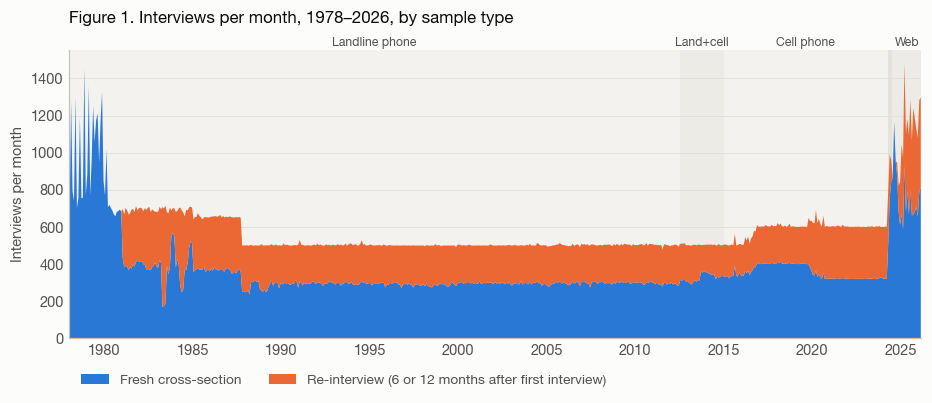

                               1970s  1980s   1990s   2000s   2010s   2020s
interviews per month (median)  954.0  663.0  501.00  501.00  506.00  604.00
re-interview share               0.0    0.4    0.42    0.41    0.36    0.41


In [2]:
g = df.groupby('YYYYMM').agg(n=('ID', 'size'), re=('IDPREV', lambda s: s.notna().sum()))
g['fresh'] = g.n - g.re
x = ym_to_date(g.index.values)
fig, ax = plt.subplots(figsize=(10, 3.4))
eras = [('1978-01-01', '2012-07-01', 'Landline phone', '#f3f2ee'), ('2012-07-01', '2015-01-01', 'Land+cell', '#ecebe6'),
        ('2015-01-01', '2024-04-01', 'Cell phone', '#f3f2ee'), ('2024-04-01', '2024-07-01', '', '#e4e2db'),
        ('2024-07-01', '2026-03-01', 'Web', '#ecebe6')]
for a, b, lab, c in eras:
    ax.axvspan(T(a), T(b), color=c, lw=0, zorder=0)
    if lab: ax.text(T(a) + (T(b) - T(a)) / 2, 1560, lab, ha='center', va='bottom', fontsize=8, color=INK2)
ax.stackplot(x, g.fresh, g.re, colors=[BLUE, ORANGE], lw=0,
             labels=['Fresh cross-section', 'Re-interview (6 or 12 months after first interview)'])
ax.set_ylim(0, 1550); ax.set_xlim(T('1978-01-01'), T('2026-03-01')); ax.grid(axis='x', visible=False)
ax.set_ylabel('Interviews per month'); ax.legend(loc='upper left', ncols=2, bbox_to_anchor=(0, -0.08))
ax.set_title('Figure 1. Interviews per month, 1978–2026, by sample type', pad=18)
plt.show()

summary = pd.DataFrame({
    'interviews per month (median)': g.n.groupby(g.index // 1000 * 10).median(),
    're-interview share': (g.re / g.n).groupby(g.index // 1000 * 10).mean().round(2)})
summary.index = [f'{i}s' for i in summary.index]
print(summary.T.to_string())

Three facts follow from Figure 1. Monthly samples were about 500 to 600 interviews for four decades and rose to roughly 1,000 to 1,300 once the survey moved to the web. Re-interviews make up 35% to 45% of most months; the panel link is not recorded before 1981. And the unit of time is the survey month, so any analysis of "the state of the economy" works with about 12 cross-sections a year, each of a few hundred to about a thousand people.

The key that identifies an interview is the pair `(YYYYMM, ID)`; `ID` alone is reused across months. A re-interview points back to its earlier interview through `IDPREV` (the earlier `ID`) and `DATEPR` (the earlier `YYYYMM`).

In [3]:
re_rows = df[df.IDPREV.notna()][['YYYYMM', 'IDPREV', 'DATEPR']]
first = df[['YYYYMM', 'ID']].rename(columns={'YYYYMM': 'DATEPR', 'ID': 'IDPREV'}).assign(found=True)
linked = re_rows.merge(first, on=['DATEPR', 'IDPREV'], how='left').found.fillna(False)
gap = (re_rows.YYYYMM // 100 * 12 + re_rows.YYYYMM % 100) - (re_rows.DATEPR // 100 * 12 + re_rows.DATEPR % 100)
print(f'{len(re_rows):,} re-interviews; {linked.mean():.5%} link to an earlier row in this file')
print('months between the two interviews:', gap.value_counts().head(3).to_dict())

124,705 re-interviews; 99.99920% link to an earlier row in this file
months between the two interviews: {6.0: 122803, 7.0: 1840, 8.0: 62}


## 1.2 How cells are coded

The file is entirely numeric. A handful of conventions cover almost every column, and they are worth learning once:

| Convention | Meaning | Example |
|---|---|---|
| Odd codes 1 / 3 / 5 | The three main answers, always in the order *better, good, up* (1); *same, pro-con, partly* (3); *worse, bad, down* (5) | `PAGO`: 1 better off, 3 same, 5 worse off |
| Codes 2 and 4 | Rare qualifiers recorded by telephone interviewers | `BUS12`: 2 "good with qualifications" |
| 8 and 9 | Don't know (DK) and not ascertained (NA, usually a refusal) | `PEXP` = 8 |
| 98 / 99, 998 / 999, 996, −97, −997 | The same DK/NA codes in two- and three-digit fields, plus "DK how much up/down" variants | `PX1` = 96 means "up, but DK by how much" |
| 9999998 and 99999998 | Missing money amounts | `HOMEAMT`, `INVAMT` |
| Blank | Not asked: the question was not in that month's questionnaire, or routing skipped it | `PX5` before 1979 |
| Triplets `…Q1`, `…Q2`, recode | Direction, then magnitude, then a signed combination | `PX1Q1` up, `PX1Q2` 4 (%), `PX1` = +4 |
| Reason codes | Open-ended "why" answers coded into favourable (10–49) and unfavourable (50–89) categories, up to two mentions | `NEWS1`, `DURRN1` |

Two cautions. First, *favourable* is not always code 1: for `UNEMP`, code 1 means "more unemployment", and for `RATEX` code 1 means "interest rates will go up". Second, the value labels for the reason codes are not in `CODEBOOK.txt`; they are in `DDI XML.txt`.

The triplet structure is easiest to see in a few rows.

In [4]:
cols = ['YYYYMM', 'PX1Q1', 'PX1Q2', 'PX1', 'PX5Q1', 'PX5Q2', 'PX5']
examples = pd.concat([df[(df.YYYY == 2023) & (df.PX1Q1 == c)].head(1) for c in [1, 3, 5, 8]])
print(examples[cols].astype('Int64').to_string(index=False))

 YYYYMM  PX1Q1  PX1Q2  PX1  PX5Q1  PX5Q2  PX5
 202301      1      3    3      1      3    3
 202301      3   <NA>    0      1      3    3
 202301      5      7   -7      2      7    7
 202301      8   <NA>   99      1      1    1


Reading across: a respondent who expects prices to go up (`PX1Q1` = 1) by some percentage (`PX1Q2`) gets that percentage in `PX1`; "same" (3) becomes 0; "down" (5) becomes a negative number; and "don't know" (8) becomes 99 in the recode. That last mapping departs from the codebook, which reserves 98 for "DK whether up or down": in the file, 98 never occurs and both DK and NA directions are coded 99, while 96 and −97 mean "up" or "down" with an unknown amount. Analyses should use the recode and treat all of these codes as missing.

## 1.3 Which questions were asked when

The questionnaire has a stable core and many modules that came and went. Figure 2 shows, for each column family and year, the share of interviews with any recorded value (a DK code counts as asked). A pale cell means the question was not asked that year; an intermediate shade usually means it was asked only of a subgroup, such as homeowners.

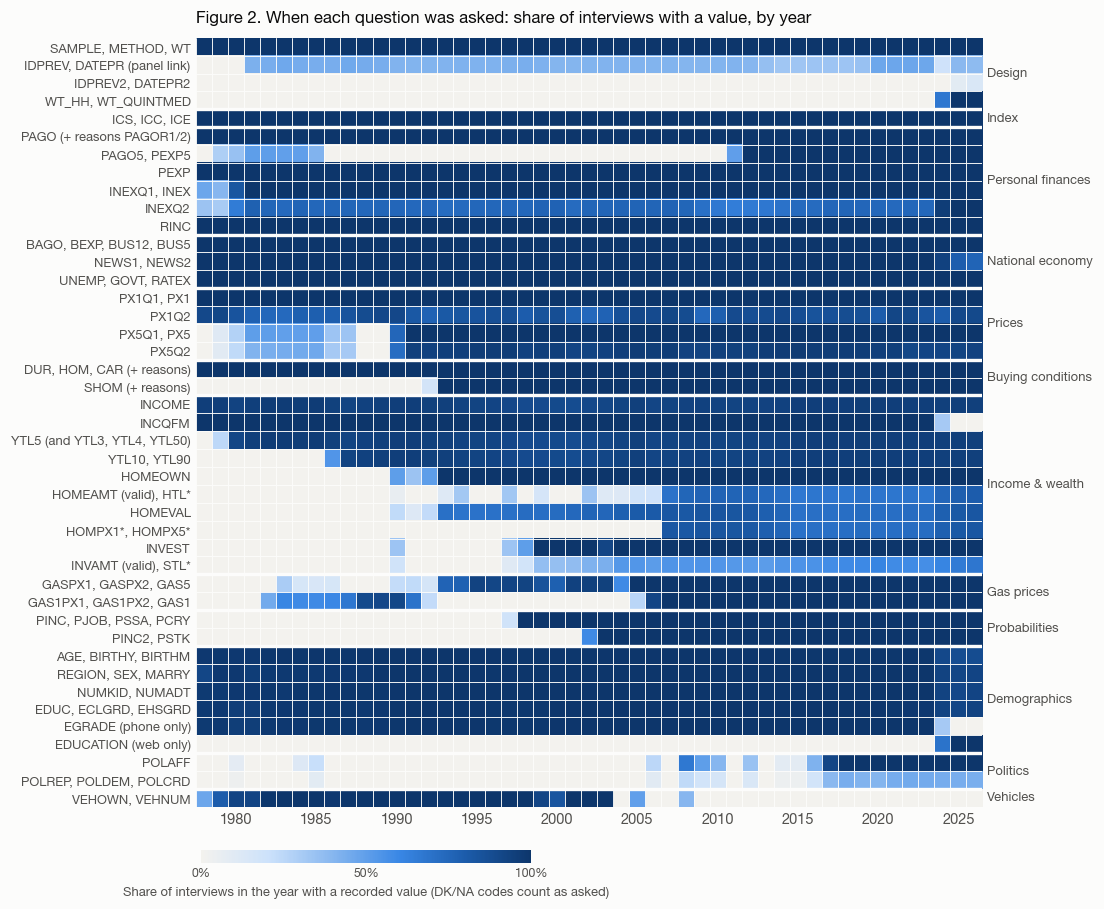

In [5]:
SENTINEL = {'HOMEAMT': 9999998, 'INVAMT': 99999998}
def asked(c):
    s = df[c]
    return (s.where(s < SENTINEL[c]) if c in SENTINEL else s).notna()
ROWS = [('Design', 'SAMPLE, METHOD, WT', 'SAMPLE'), ('Design', 'IDPREV, DATEPR (panel link)', 'IDPREV'),
 ('Design', 'IDPREV2, DATEPR2', 'IDPREV2'), ('Design', 'WT_HH, WT_QUINTMED', 'WT_QUINTMED'),
 ('Index', 'ICS, ICC, ICE', 'ICS'),
 ('Personal finances', 'PAGO (+ reasons PAGOR1/2)', 'PAGO'), ('Personal finances', 'PAGO5, PEXP5', 'PAGO5'),
 ('Personal finances', 'PEXP', 'PEXP'), ('Personal finances', 'INEXQ1, INEX', 'INEXQ1'),
 ('Personal finances', 'INEXQ2', 'INEXQ2'), ('Personal finances', 'RINC', 'RINC'),
 ('National economy', 'BAGO, BEXP, BUS12, BUS5', 'BUS12'), ('National economy', 'NEWS1, NEWS2', 'NEWS1'),
 ('National economy', 'UNEMP, GOVT, RATEX', 'UNEMP'),
 ('Prices', 'PX1Q1, PX1', 'PX1Q1'), ('Prices', 'PX1Q2', 'PX1Q2'), ('Prices', 'PX5Q1, PX5', 'PX5Q1'), ('Prices', 'PX5Q2', 'PX5Q2'),
 ('Buying conditions', 'DUR, HOM, CAR (+ reasons)', 'DUR'), ('Buying conditions', 'SHOM (+ reasons)', 'SHOM'),
 ('Income & wealth', 'INCOME', 'INCOME'), ('Income & wealth', 'INCQFM', 'INCQFM'), ('Income & wealth', 'YTL5 (and YTL3, YTL4, YTL50)', 'YTL5'),
 ('Income & wealth', 'YTL10, YTL90', 'YTL10'), ('Income & wealth', 'HOMEOWN', 'HOMEOWN'),
 ('Income & wealth', 'HOMEAMT (valid), HTL*', 'HOMEAMT'), ('Income & wealth', 'HOMEVAL', 'HOMEVAL'),
 ('Income & wealth', 'HOMPX1*, HOMPX5*', 'HOMPX1Q1'), ('Income & wealth', 'INVEST', 'INVEST'),
 ('Income & wealth', 'INVAMT (valid), STL*', 'INVAMT'),
 ('Gas prices', 'GASPX1, GASPX2, GAS5', 'GASPX1'), ('Gas prices', 'GAS1PX1, GAS1PX2, GAS1', 'GAS1PX1'),
 ('Probabilities', 'PINC, PJOB, PSSA, PCRY', 'PINC'), ('Probabilities', 'PINC2, PSTK', 'PINC2'),
 ('Demographics', 'AGE, BIRTHY, BIRTHM', 'AGE'), ('Demographics', 'REGION, SEX, MARRY', 'MARRY'),
 ('Demographics', 'NUMKID, NUMADT', 'NUMKID'), ('Demographics', 'EDUC, ECLGRD, EHSGRD', 'EDUC'),
 ('Demographics', 'EGRADE (phone only)', 'EGRADE'), ('Demographics', 'EDUCATION (web only)', 'EDUCATION'),
 ('Politics', 'POLAFF', 'POLAFF'), ('Politics', 'POLREP, POLDEM, POLCRD', 'POLCRD'), ('Vehicles', 'VEHOWN, VEHNUM', 'VEHOWN')]
years = np.arange(1978, 2027)
M = np.array([[asked(c)[df.YYYY == y].mean() for y in years] for _, _, c in ROWS])
fig, ax = plt.subplots(figsize=(10, 9.2))
ax.imshow(M, aspect='auto', cmap=SEQ, vmin=0, vmax=1, interpolation='nearest')
groups = [r[0] for r in ROWS]
for x0 in np.arange(-0.5, len(years), 1): ax.axvline(x0, color=SURFACE, lw=0.6)
for i in range(1, len(ROWS)): ax.axhline(i - 0.5, color=SURFACE, lw=2.2 if groups[i] != groups[i - 1] else 0.6)
ax.set_yticks(range(len(ROWS))); ax.set_yticklabels([r[1] for r in ROWS], fontsize=8.5)
xt = [i for i, y in enumerate(years) if y % 5 == 0]; ax.set_xticks(xt); ax.set_xticklabels(years[xt]); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
start = 0
for i in range(1, len(ROWS) + 1):
    if i == len(ROWS) or groups[i] != groups[i - 1]:
        ax.text(len(years) - 0.2, (start + i - 1) / 2, groups[start], va='center', fontsize=8.5, color=INK2, fontweight='semibold')
        start = i
cax = fig.add_axes([0.13, 0.065, 0.3, 0.012])
cb = fig.colorbar(mpl.cm.ScalarMappable(cmap=SEQ, norm=mpl.colors.Normalize(0, 1)), cax=cax, orientation='horizontal')
cb.outline.set_visible(False); cb.set_ticks([0, .5, 1]); cb.set_ticklabels(['0%', '50%', '100%']); cb.ax.tick_params(labelsize=8)
cb.set_label('Share of interviews in the year with a recorded value (DK/NA codes count as asked)', fontsize=8.5, color=INK2)
ax.set_title('Figure 2. When each question was asked: share of interviews with a value, by year', pad=10)
fig.subplots_adjust(bottom=0.12, right=0.84); plt.show()

The figure carries three messages. About two dozen questions, including all five items of the sentiment index, the other national-economy questions and the inflation expectation, were asked in essentially every interview for 48 years; this core is what makes long time-series work possible. Many other modules were added late (the probability questions in 1997 and 2002, home-price expectations in 2007) or dropped (vehicle ownership after 2008). And party identification (`POLAFF`) was asked only sporadically until February 2017, after which it is in every month. Because partisanship turns out to be central to how answers respond to the economy (Section 1.6), February 2017 is the practical start of any analysis that needs it.

## 1.4 Column-by-column guide

The tables below cover every column, grouped by family. The last column gives a recommendation for this project: **Core** marks the variables the proposed experiment is built on, **Use** marks variables worth carrying as features, controls or secondary targets, and **Skip** marks variables that are unlikely to be used, with the reason. "All" in the availability column means every month from January 1978 to February 2026.

**A. Design, identifiers and weights**

| Column | What it is | Values | Availability | Notes and recommendation |
|---|---|---|---|---|
| `CASEID` | Row number in this extract | 1–342,345 | All | Not stable across downloads; never a person key. **Skip.** |
| `YYYYMM`, `YYYYQ`, `YYYY` | Survey month, quarter, year | e.g. 202504 | All | A survey "month" is an interview window that opens in the last week of the previous calendar month (Section 1.5). **Core.** |
| `ID` | Interview ID | integer | All | Unique only together with `YYYYMM`. **Core** (key). |
| `IDPREV`, `DATEPR` | `ID` and `YYYYMM` of the respondent's previous interview | | 36% of rows, from 1981 | Every link resolves to an earlier row, almost always six months earlier. Web re-interviews from April 2024 to January 2025 often lack the link because their first interview was in the experimental web panel, which is not public. **Core** (panel). |
| `IDPREV2`, `DATEPR2` | Link to the first interview, for third interviews | | 2025–2026 only | Earlier third interviews can be chained through `IDPREV`. **Use.** |
| `SAMPLE` | Sampling frame × interview number | 1–8 | All | 1–2 landline fresh / re-interview; 3–5 cell fresh / re-interview / second re-interview; 6–8 web fresh / first / second re-interview. **Use.** |
| `METHOD` | Mode of interview | 1 phone (computer-assisted), 2 web, 3 phone (paper, 1978–93) | All | The flag for the 2024 mode change. **Core.** |
| `WT` | Weight used for official estimates, mean 1 | 0–14.6 | All | About 5% of rows before 2014 have weight 0 (respondents who are neither a household head nor a spouse). Use for every population statistic. **Core.** |
| `WT_HH`, `WT_QUINTMED` | Alternative weights | | 2024 onward | `WT` equals `WT_QUINTMED` for web interviews. **Skip** unless replicating the weighting. |

**B. Index scores**

| Column | What it is | Values | Availability | Notes and recommendation |
|---|---|---|---|---|
| `ICS`, `ICC`, `ICE` | The Index of Consumer Sentiment and its current-conditions and expectations components, computed from this respondent's own answers | A dozen discrete values (2.0 = all answers unfavourable, about 150 = all favourable) | All | Deterministic functions of `PAGO`, `PEXP`, `BUS12`, `BUS5` and `DUR`. Their `WT`-weighted monthly mean reproduces the published index (Figure 3). **Skip** as targets because they are derived; **Use** to aggregate predicted answers into an index. |

**C. Personal finances**

| Column | What it is | Values | Availability | Notes and recommendation |
|---|---|---|---|---|
| `PAGO` | Better or worse off than a year ago | 1 / 3 / 5, 8, 9 | All | Index item. **Use** (secondary target). |
| `PAGOR1`, `PAGOR2` | Reasons for `PAGO`, coded | 0, favourable 10–39, unfavourable 50–78, 333 "no change" (web) | All | Rich, but coding depends on mode. **Skip** for now; useful later as auxiliary signals. |
| `PAGO5`, `PEXP5` | Better or worse off than 5 years ago / in 5 years | 1 / 3 / 5 | 1979–1985 and 2011 onward | **Skip.** |
| `PEXP` | Better or worse off a year from now | 1 / 3 / 5, 8, 9 | All | Index item; among the least state-dependent questions (Figure 6). **Core** target, as a contrast case. |
| `INEXQ1`, `INEXQ2`, `INEX` | Expected change in family income over 12 months: direction, percent, signed recode | | All (`INEXQ2` only if a change is expected) | Phone and web answers diverge badly; Michigan reports a phone–web time-series correlation of 0.14. **Skip.** |
| `RINC` | Income will rise more, the same, or less than prices over 1–2 years | 1 / 3 / 5 | All | **Use** (secondary target). |

**D. The national economy**

| Column | What it is | Values | Availability | Notes and recommendation |
|---|---|---|---|---|
| `BUS12` | Good or bad times for business in the next 12 months | 1, 2, 3, 4, 5, 8, 9 | All | Index item; strongly state- and party-dependent. The web version offers "partly good and partly bad" explicitly, so the middle answer rises from about 6% to about 47% (Figure 5). **Core** target. |
| `BUS5` | Continuous good times vs periods of widespread unemployment over 5 years | 1–5, 98, 99 | All | Index item with an even larger middle-option shift on the web. **Use** (secondary). |
| `BAGO`, `BEXP` | Business conditions compared with a year ago / a year from now | 1 / 3 / 5 | All | `BAGO` is the most state-dependent question in the file. **Use** (secondary). |
| `UNEMP` | More, the same, or less unemployment next year | 1 more, 3, 5 less | All | Code 1 is the unfavourable answer. **Use** (secondary). |
| `GOVT` | Government's economic policy: good, only fair, poor | 1 / 3 / 5 | All | Driven by party interacted with who holds the White House (Figure 7). **Core** target. |
| `RATEX` | Interest rates will go up, stay, or go down | 1 up, 3, 5 down | All | **Use** (secondary). |
| `NEWS1`, `NEWS2` | Economic news the respondent recalls hearing, coded | 0 none; favourable 10–49; unfavourable 50–90; 97–99 | All; about 77% filled in the web era | A direct measure of what news reached respondents. It is itself an answer, so it must not be used as an input for predicting the same interview. **Skip** for the MVP; valuable later for auditing news inputs. |

**E. Prices**

| Column | What it is | Values | Availability | Notes and recommendation |
|---|---|---|---|---|
| `PX1Q1` | Prices will go up, stay the same, or go down over 12 months | 1, 2 (up at the same rate), 3, 5, 8, 9 | All | Direction step. |
| `PX1Q2` | By what percent | 1–95; 98, 99 | Asked if up or down | Magnitude step; phone interviewers and the web form both double-check answers of 5% or more. |
| `PX1` | Signed year-ahead expected inflation | −95 to 95; 0 = same; −97, 96, 98, 99 are DK/NA | All | Answers heap on 0, 2, 3, 5 and 10 (Figure 4). The published headline is the weighted median. **Core** target (in five bins). |
| `PX5Q1`, `PX5Q2`, `PX5` | The same for the next 5 to 10 years, per year | as above | From 1979; complete from 1990 | Long-run expectations move less. **Use** (secondary). |

**F. Buying conditions**

| Column | What it is | Values | Availability | Notes and recommendation |
|---|---|---|---|---|
| `DUR` (+ `DURRN1/2`) | Good or bad time to buy major household items (+ coded reasons) | 1 / 3 / 5 | All | Index item; the web version has almost no middle answers. **Use** (secondary). |
| `HOM` (+ `HOMRN1/2`) | Good or bad time to buy a house | 1 / 3 / 5 | All | Very state-dependent (rates, prices). **Use** (secondary). |
| `SHOM` (+ `SHOMRN1/2`) | Good or bad time to sell a house | 1 / 3 / 5 | 1992 onward | **Use** (secondary). |
| `CAR` (+ `CARRN1/2`) | Good or bad time to buy a vehicle | 1 / 3 / 5 | All | **Use** (secondary). Reason codes: **Skip** for the MVP. |

**G. Income, wealth and housing**

| Column | What it is | Values | Availability | Notes and recommendation |
|---|---|---|---|---|
| `INCOME` | Household income last year, dollars | 0–500,000 | About 94% of rows | Bracketed answers are coded to bracket midpoints; top-coded at $500,000 (a few 2024 rows show 999,999). **Use.** |
| `INCQFM`, `HOMEQFM`, `INVQFM` | Whether an amount was given exactly or as a bracket | 1 / 2 / 3 | Set to missing for all web interviews (pending re-creation by Michigan) | **Skip.** |
| `YTL10`, `YTL90`, `YTL50`, `YTL5`, `YTL4`, `YTL3` | The respondent's position in that year's income distribution | quantile codes | 1979 or 1986 onward | `YTL5` (quintile) is the convenient profile variable. **Use** (`YTL5`). |
| `HOMEOWN` | Owns or rents | 1, 2, 99 | 1990 onward, complete from 1993 | **Use.** |
| `HOMEAMT`, `HTL*` | Home value in dollars, and its quantiles | 9999998 = missing | Owners, mostly 2007 onward | Treat 9999998 as missing (Michigan user note, September 2026). **Skip.** |
| `HOMEVAL` | Home value up, same or down over the past year | 1 / 3 / 5 | Owners, 1990 onward | **Skip.** |
| `HOMPX1*`, `HOMPX5*` | Expected change in local home prices over 1 and 5 years (triplets) | 998, 999 = DK/NA | Owners, 2007 onward | Decimal errors corrected in March 2026. A good future target. **Skip** for the MVP. |
| `INVEST` | Household holds stocks | 1 yes; 5 no (includes DK and NA) | 1999 onward, sporadic earlier | **Use.** |
| `INVAMT`, `STL*` | Value of stock holdings, and its quantiles | 99999998 = missing | Holders, 2000s onward | **Skip.** |

**H. Gasoline prices**

| Column | What it is | Values | Availability | Notes and recommendation |
|---|---|---|---|---|
| `GASPX1`, `GASPX2`, `GAS5` | Gas prices up, same or down over 5 years; cents; signed recode | 995 = 995 cents or more | 1993 onward | **Skip** for the MVP; a natural target for the 2026 oil-price shock. |
| `GAS1PX1`, `GAS1PX2`, `GAS1` | The same over 12 months | as above | 1982–1992 and 2006 onward | As above. |

**I. Probability questions** (0–100 percent chance; 998, 999 = DK/NA)

| Column | What it is | Availability | Notes and recommendation |
|---|---|---|---|
| `PINC` | Chance that income beats inflation over 5 years | 1997 onward | **Skip.** |
| `PINC2` | Chance that income is higher in 12 months (996 = "no personal income", phone only) | 2002 onward | **Skip.** |
| `PJOB` | Chance that the respondent or spouse loses a job in 5 years | 1997 onward | Decimal errors corrected March 2026. **Use** later. |
| `PSSA` | Chance that Social Security and pensions will be adequate | 1997 onward | **Skip.** |
| `PCRY` | Chance of a comfortable retirement, up / same / down vs 5 years ago (1 / 3 / 5) | 1997 onward | **Skip.** |
| `PSTK` | Chance that a diversified stock fund gains value over a year | 2002 onward | **Use** later (market expectations). |

**J. Demographics**

| Column | What it is | Values | Availability | Notes and recommendation |
|---|---|---|---|---|
| `AGE`, `BIRTHY`, `BIRTHM` | Age; year and month of birth | 18–97 | About 99% by phone, 87% on the web | `BIRTHY` gives the birth cohort, which matters for experience-based models of inflation expectations. **Use.** |
| `REGION` | Census region | 1 West, 2 North Central (Midwest), 3 Northeast, 4 South | All | **Use.** |
| `SEX` | 1 male, 2 female | | About 99% by phone, 91% on the web | **Use.** |
| `MARRY` | 1 married or partnered, 3 divorced or separated, 4 widowed, 5 never married | | About 98% | **Use.** |
| `NUMKID`, `NUMADT` | Children under 18 and adults in the household | 0–5 (top-coded) | About 99% | `NUMKID` was revised in 2026 to separate "none" from "no answer" in web data. **Use.** |
| `EDUC` | Education, harmonised across modes | 1 grade 0–8; 2 some high school; 3 high-school diploma; 4 some college; 5 college degree; 6 postgraduate | About 98% | The web sample is far more educated than the phone sample before weighting. **Use.** |
| `ECLGRD`, `EHSGRD` | College graduate; high-school graduate | 1 / 5 / 8 / 9 | All | Redundant with `EDUC`. **Skip.** |
| `EGRADE` | Highest grade completed (phone only) | years | Through June 2024 | **Skip.** |
| `EDUCATION` | Highest degree (web only) | 1–8 | April 2024 onward | Finer than `EDUC` but not comparable over time. **Skip.** |

**K. Politics**

| Column | What it is | Values | Availability | Notes and recommendation |
|---|---|---|---|---|
| `POLAFF` | Party identification | 1 Republican, 2 Democrat, 3 independent; 8, 9 | Every month from February 2017; scattered before | **Core.** |
| `POLREP`, `POLDEM`, `POLCRD` | Strength of partisanship; which party an independent leans toward | 1 / 5 (strong / not so strong); 1 / 5 / 6 (Republican / Democrat / neither) | Follow-ups to `POLAFF` | Combined into a seven-point party scale. **Core.** |

**L. Vehicles**

| Column | What it is | Availability | Notes and recommendation |
|---|---|---|---|
| `VEHOWN`, `VEHNUM` | Owns or leases a vehicle; how many | 1978–2008 | Discontinued. **Skip.** |

## 1.5 Quirks that matter for any analysis

**A survey month is an interview window, not a calendar month.** Interviews for month *m* start in the last week of month *m − 1* and end around the 20th of *m*. The official windows are in `Release and Interview Dates.pdf`, transcribed here to `data/external/sca/interview_windows.csv`. The April 2025 survey, for example, was in the field from 25 March to 21 April, so it straddles the 2 April tariff announcement. Any macro data or news attached to respondents must be dated to this window, and must be what was public at the time.

In [6]:
win = pd.read_csv(DATA / 'external' / 'sca' / 'interview_windows.csv')
print(win[win.YYYYMM.between(202501, 202506)].to_string(index=False))

 YYYYMM prelim_release final_release interview_start interview_end
 202501     2025-01-10    2025-01-24      2024-12-17    2025-01-20
 202502     2025-02-07    2025-02-21      2025-01-21    2025-02-17
 202503     2025-03-14    2025-03-28      2025-02-18    2025-03-24
 202504     2025-04-11    2025-04-25      2025-03-25    2025-04-21
 202505     2025-05-16    2025-05-30      2025-04-22    2025-05-26
 202506     2025-06-13    2025-06-27      2025-05-27    2025-06-23


**The index columns can be trusted, and the weights are what make them work.** As a check on both the coding and the weights, Figure 3 averages the respondent-level index score `ICS` with `WT` in each month and lays it over the official series published by FRED.

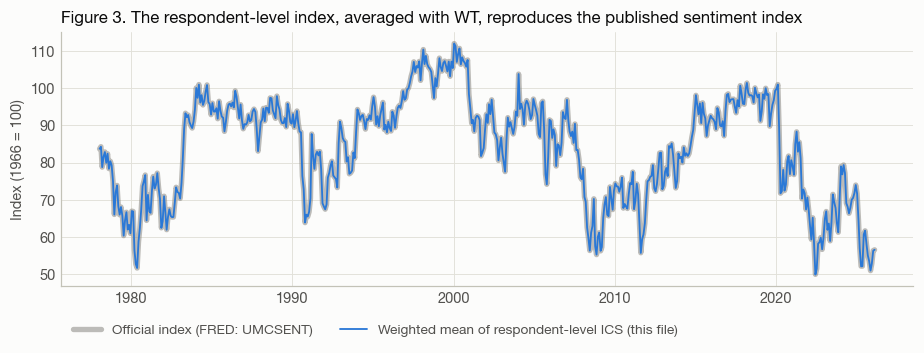

mean absolute difference 0.025 index points; max 0.12


In [7]:
ics = df[df.WT > 0].groupby('YYYYMM').apply(lambda g: np.average(g.ICS, weights=g.WT))
off = read_fred('UMCSENT'); off.index = off.index.year * 100 + off.index.month
j = pd.concat([ics.rename('micro'), off.rename('official')], axis=1).dropna()
fig, ax = plt.subplots(figsize=(10, 3.0))
x = ym_to_date(j.index.values)
ax.plot(x, j.official, color=MUTED, lw=3.5, alpha=0.55, label='Official index (FRED: UMCSENT)')
ax.plot(x, j.micro, color=BLUE, lw=1.2, label='Weighted mean of respondent-level ICS (this file)')
ax.set_ylabel('Index (1966 = 100)'); ax.legend(loc='upper left', bbox_to_anchor=(0, -0.1), ncols=2)
ax.set_title('Figure 3. The respondent-level index, averaged with WT, reproduces the published sentiment index')
plt.show()
print(f'mean absolute difference {np.abs(j.micro - j.official).mean():.3f} index points; max {np.abs(j.micro - j.official).max():.2f}')

The two lines are indistinguishable; the largest monthly gap is a rounding-sized 0.12 points. The file therefore contains exactly what the official numbers are built from, and the official headline is a weighted average of five three-way answers.

**Inflation expectations are heaped and track inflation with a floor.** Figure 4 shows the year-ahead expectation (`PX1`). Nearly two-thirds of answers fall on 0, 2, 3, 5 or 10 percent, so the median moves in visible steps; Michigan's published median interpolates within the heaps, as does the median below. Over time, expectations follow realised inflation in the high-inflation episodes (1979–81 and 2021–23) but rarely fall below about 2 to 3 percent when inflation is low.

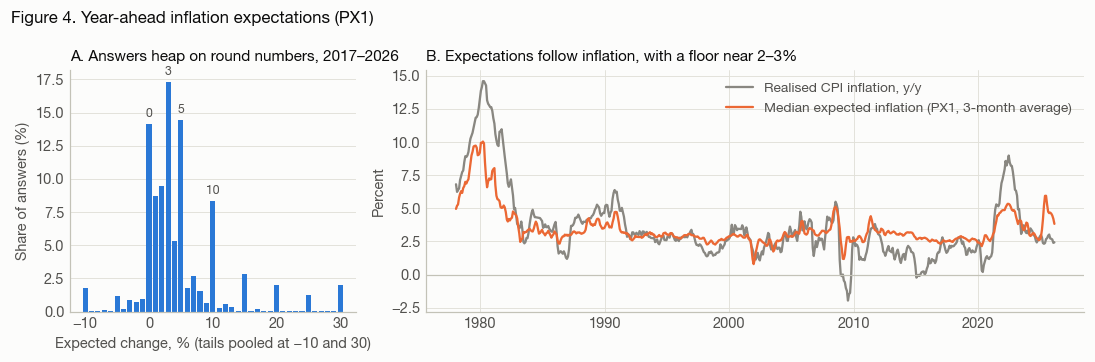

In [8]:
px = df.PX1.where(df.PX1.between(-95, 95))
d4 = df.assign(px=px).dropna(subset=['px'])
med = d4[d4.WT > 0].groupby('YYYYMM').apply(lambda g: grouped_median(g.px, g.WT))
cpi = read_fred('CPIAUCSL').pct_change(12) * 100; cpi.index = cpi.index.year * 100 + cpi.index.month
fig, axs = plt.subplots(1, 2, figsize=(10, 3.3), gridspec_kw={'width_ratios': [1, 2.3]})
ax = axs[0]
cnt = d4[d4.YYYY >= 2017].px.clip(-10, 30).round().value_counts(normalize=True).sort_index() * 100
ax.bar(cnt.index, cnt.values, width=0.8, color=BLUE)
for k in [0, 3, 5, 10]: ax.text(k, cnt.get(k, 0) + 0.5, f'{k}', ha='center', fontsize=8, color=INK2)
ax.set_xlabel('Expected change, % (tails pooled at −10 and 30)'); ax.set_ylabel('Share of answers (%)'); ax.grid(axis='x', visible=False)
ax.set_title('A. Answers heap on round numbers, 2017–2026', fontsize=10)
ax = axs[1]
cc = cpi.loc[197801:202602]
ax.plot(ym_to_date(cc.index.values), cc.values, color=MUTED, lw=1.5, label='Realised CPI inflation, y/y')
ax.plot(ym_to_date(med.index.values), med.rolling(3, min_periods=1).mean().values, color=ORANGE, lw=1.5,
        label='Median expected inflation (PX1, 3-month average)')
ax.axhline(0, color=AXIS, lw=0.8); ax.set_ylabel('Percent'); ax.legend(loc='upper right')
ax.set_title('B. Expectations follow inflation, with a floor near 2–3%', fontsize=10)
fig.suptitle('Figure 4. Year-ahead inflation expectations (PX1)', x=0.01, ha='left', fontsize=11, fontweight='semibold')
fig.tight_layout(); plt.show()

**The 2024 switch from telephone to web changed the answers, not just the channel.** From April to June 2024 the survey ran both modes in parallel and published a blend; from July 2024 it is web only. Because the same months were fielded both ways, the overlap months isolate the effect of the mode itself. Figure 5 compares weighted answers by mode in those three months.

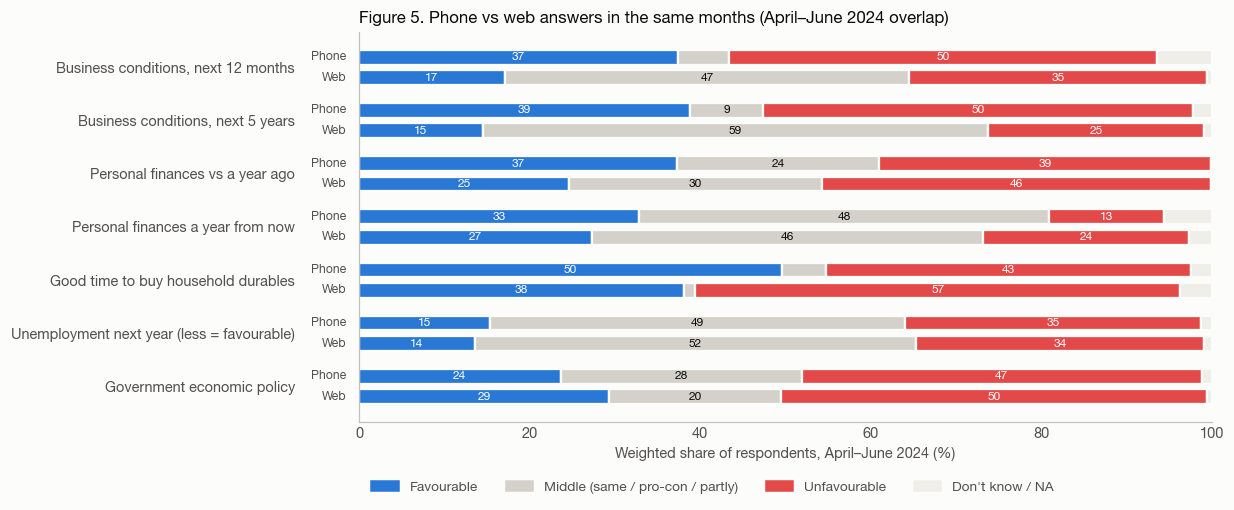

In [9]:
ov = df[df.YYYYMM.between(202404, 202406)]
Q5 = [('BUS12', 'Business conditions, next 12 months', [1, 2], [3], [4, 5], [8, 9]),
      ('BUS5', 'Business conditions, next 5 years', [1, 2], [3], [4, 5], [98, 99]),
      ('PAGO', 'Personal finances vs a year ago', [1], [3], [5], [8, 9]),
      ('PEXP', 'Personal finances a year from now', [1], [3], [5], [8, 9]),
      ('DUR', 'Good time to buy household durables', [1], [3], [5], [8, 9]),
      ('UNEMP', 'Unemployment next year (less = favourable)', [5], [3], [1], [8, 9]),
      ('GOVT', 'Government economic policy', [1], [3], [5], [8, 9])]
col = {'F': BLUE, 'M': NEUTRAL, 'U': RED, 'D': '#efeee9'}
fig, ax = plt.subplots(figsize=(10, 4.6)); y = 0; yt = []
for q, lab, f, m, u, dk in Q5:
    for meth, name in [(1, 'Phone'), (2, 'Web')]:
        g = ov[ov.METHOD == meth]
        codes = g[q].replace({**{c: 'F' for c in f}, **{c: 'M' for c in m}, **{c: 'U' for c in u}, **{c: 'D' for c in dk}})
        s = wshare(codes.values, g.WT, ['F', 'M', 'U', 'D']); left = 0
        for k, v in zip('FMUD', s):
            ax.barh(y, v * 100, left=left, height=0.72, color=col[k], edgecolor=SURFACE, linewidth=1.5)
            if v > 0.07: ax.text(left + v * 50, y, f'{v*100:.0f}', ha='center', va='center', fontsize=7.8, color='white' if k in 'FU' else INK)
            left += v * 100
        ax.text(-1.5, y, name, ha='right', va='center', fontsize=8, color=INK2); y += 1
    yt.append(y - 1.5); y += 0.6
ax.set_yticks(yt); ax.set_yticklabels([q[1] for q in Q5]); ax.tick_params(axis='y', pad=42)
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.grid(False); ax.set_xlabel('Weighted share of respondents, April–June 2024 (%)')
ax.legend(handles=[Patch(color=col[k], label=l) for k, l in zip('FMUD', ['Favourable', 'Middle (same / pro-con / partly)', 'Unfavourable', "Don't know / NA"])],
          loc='upper left', bbox_to_anchor=(0, -0.12), ncols=4)
ax.set_title('Figure 5. Phone vs web answers in the same months (April–June 2024 overlap)')
plt.show()

The effects are large and question-specific. When the web form lists "partly good and partly bad" as an option, the middle answer to the business-conditions questions jumps from under 10% to roughly half; on the phone that answer had to be volunteered. Web respondents are also more negative about their own finances and about buying conditions, consistent with the survey methodology finding that people report more favourably to a friendly interviewer. "Don't know" nearly disappears, because the web form does not display it. Interestingly, the *net* balance (favourable minus unfavourable) moves much less than the three-way distribution, which is why the published indexes survived the transition with a modest level shift (Michigan estimates −6.6 index points on average).

The practical rule is that **answer distributions from the two modes must never be pooled or compared without a mode term**, and the overlap months are the only place where that term can be estimated cleanly. Web re-interviews cannot help here, since no phone respondent was re-interviewed on the web.

**Smaller quirks worth knowing.**

* *Composition.* Before weighting, web respondents are much more educated and more often homeowners than phone respondents were; the weights (`WT`, raked to Census population totals) correct the marginal distributions, not necessarily the joint ones. Michigan also reports that the Republican share of the sample fell after the 2025 presidential transition and attributes this to respondent behaviour rather than to the web method. Party is not a weighting variable.
* *Missing in the web era.* Age, sex and birth date are missing for about 9% to 13% of web interviews, and the bracket-format flags (`INCQFM` and its siblings) are temporarily blank for all web rows.
* *Revisions.* The archive is revised in place: decimal errors in `PJOB`, `PSSA`, `PSTK` and the home-price variables were fixed in March 2026, and a small number of 2024–25 inflation answers were re-edited. Results should record the download date.
* *External data gaps.* The October 2025 government shutdown cancelled the October CPI and unemployment releases. Any macro feature for November 2025 must use what was actually public (the last available number), not an interpolation from later data.

## 1.6 How much of an answer is the economy, and how much is the person?

The two Simile papers that motivate this project evaluate predictions of attitudes and choices that mostly reflect *who a person is*. Most questions in this survey are of a different kind: the same person gives different answers in different months because the economy has changed. This section measures that directly, by splitting the individual-level variance of each answer into four parts.

* **Month**: the variance of monthly means, that is, what everyone in a month shares.
* **Demographics**: what age, sex, education, region, income quintile and marital status explain within a month.
* **Stable person-specific**: the part of the remaining answer that is correlated with the same person's answer six months later, estimated from re-interview pairs.
* **Transient**: everything else, including measurement noise.

Answers are coded +1 (favourable), 0 (middle) and −1 (unfavourable); the inflation expectation is used as a number, capped at −5 and 25. The calculation uses the telephone years 1980–2023 only, so the mode is constant.

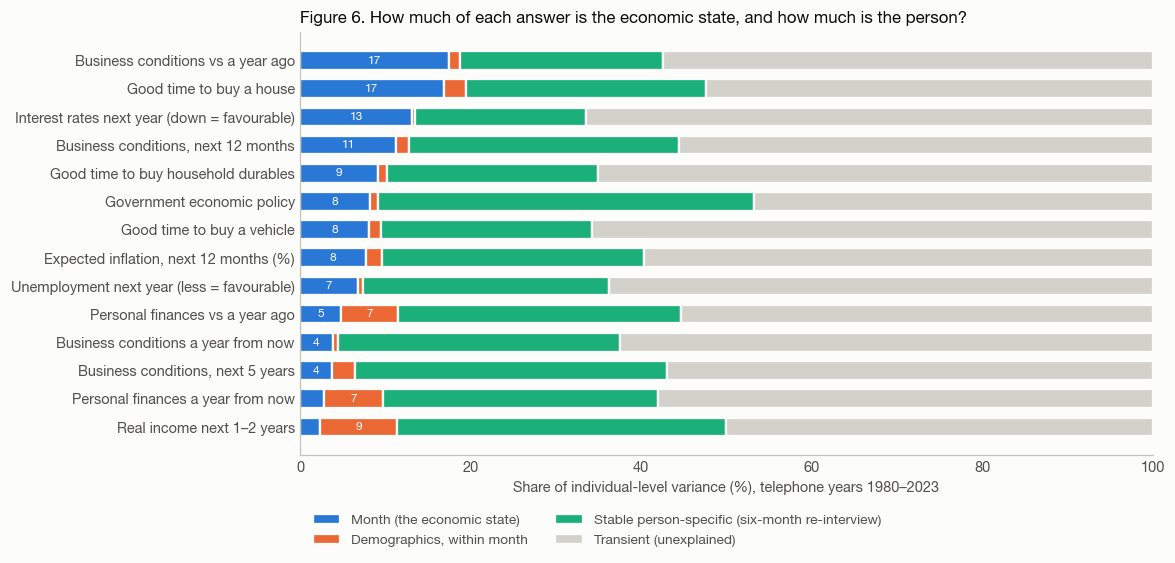

       month  demographics  person  transient
q                                            
BAGO   0.175         0.012   0.238      0.575
HOM    0.168         0.027   0.281      0.524
RATEX  0.131         0.003   0.201      0.665
BUS12  0.113         0.015   0.317      0.555
DUR    0.091         0.011   0.247      0.651
GOVT   0.082         0.010   0.441      0.467
CAR    0.080         0.015   0.247      0.658
PX1    0.077         0.019   0.307      0.597
UNEMP  0.068         0.006   0.288      0.638
PAGO   0.048         0.067   0.332      0.554
BEXP   0.038         0.007   0.331      0.625
BUS5   0.038         0.027   0.365      0.570
PEXP   0.027         0.070   0.322      0.581
RINC   0.024         0.090   0.386      0.501


In [10]:
def tri(s, fav, mid, unf):
    out = pd.Series(np.nan, index=s.index)
    out[s.isin(fav)] = 1; out[s.isin(mid)] = 0; out[s.isin(unf)] = -1
    return out
SCORED = {'BAGO': ('Business conditions vs a year ago', [1], [3], [5]), 'HOM': ('Good time to buy a house', [1], [3], [5]),
    'RATEX': ('Interest rates next year (down = favourable)', [5], [3], [1]), 'BUS12': ('Business conditions, next 12 months', [1, 2], [3], [4, 5]),
    'DUR': ('Good time to buy household durables', [1], [3], [5]), 'CAR': ('Good time to buy a vehicle', [1], [3], [5]),
    'GOVT': ('Government economic policy', [1], [3], [5]), 'UNEMP': ('Unemployment next year (less = favourable)', [5], [3], [1]),
    'BEXP': ('Business conditions a year from now', [1], [3], [5]), 'BUS5': ('Business conditions, next 5 years', [1, 2], [3], [4, 5]),
    'PAGO': ('Personal finances vs a year ago', [1], [3], [5]), 'PEXP': ('Personal finances a year from now', [1], [3], [5]),
    'RINC': ('Real income next 1–2 years', [1], [3], [5])}
for q, (lab, f, m, u) in SCORED.items(): df['y_' + q] = tri(df[q], f, m, u)
df['y_PX1'] = df.PX1.where(df.PX1.between(-95, 95)).clip(-5, 25); SCORED['PX1'] = ('Expected inflation, next 12 months (%)',)
df['agebin'] = pd.cut(df.AGE, [0, 34, 49, 64, 120], labels=False)
DEMO = ['agebin', 'SEX', 'EDUC', 'REGION', 'YTL5', 'MARRY']

def demean_by_month(d, X):
    return X - X.groupby(d.YYYYMM).transform('mean')
rows = []
base = df[df.YYYY.between(1980, 2023)]
for q in SCORED:
    d = base.dropna(subset=['y_' + q] + DEMO).copy(); y = 'y_' + q
    tot = d[y].var()
    yc = d[y] - d.groupby('YYYYMM')[y].transform('mean')
    X = demean_by_month(d, pd.get_dummies(d[DEMO].astype(int).astype(str), drop_first=True).astype(float))
    b, *_ = np.linalg.lstsq(X.values, yc.values, rcond=None)
    d['r'] = yc.values - X.values @ b
    prev = d[['YYYYMM', 'ID', 'r']].rename(columns={'YYYYMM': 'DATEPR', 'ID': 'IDPREV', 'r': 'r_prev'})
    pairs = d[d.IDPREV.notna()][['DATEPR', 'IDPREV', 'r']].merge(prev, on=['DATEPR', 'IDPREV'])
    rho = np.corrcoef(pairs.r, pairs.r_prev)[0, 1]; resid = d.r.var() / tot
    rows.append(dict(q=q, label=SCORED[q][0], month=(tot - yc.var()) / tot, demographics=(yc.var() - d.r.var()) / tot,
                     person=rho * resid, transient=(1 - rho) * resid, n=len(d), pairs=len(pairs)))
DEC = pd.DataFrame(rows).set_index('q').sort_values('month')
fig, ax = plt.subplots(figsize=(10, 5.0)); left = np.zeros(len(DEC))
parts = [('month', 'Month (the economic state)', BLUE), ('demographics', 'Demographics, within month', ORANGE),
         ('person', 'Stable person-specific (six-month re-interview)', AQUA), ('transient', 'Transient (unexplained)', NEUTRAL)]
for k, lab, c in parts:
    ax.barh(range(len(DEC)), DEC[k] * 100, left=left, color=c, height=0.66, edgecolor=SURFACE, linewidth=1.5, label=lab)
    if k in ('month', 'demographics'):
        for i, (v, l0) in enumerate(zip(DEC[k], left)):
            if v > 0.035: ax.text(l0 + v * 50, i, f'{v*100:.0f}', ha='center', va='center', fontsize=7.8, color='white')
    left += DEC[k].values * 100
ax.set_yticks(range(len(DEC))); ax.set_yticklabels(DEC.label); ax.set_xlim(0, 100); ax.grid(False)
ax.set_xlabel('Share of individual-level variance (%), telephone years 1980–2023')
ax.legend(loc='upper left', bbox_to_anchor=(0, -0.11), ncols=2)
ax.set_title('Figure 6. How much of each answer is the economic state, and how much is the person?')
plt.show()
print(DEC[['month', 'demographics', 'person', 'transient']].round(3).iloc[::-1].to_string())

Three results stand out. First, **for 11 of the 14 questions the survey month explains more of an individual's answer than all six demographic variables together**, often several times more (17% vs 1% for business conditions compared with a year ago). Only the three questions about one's own income and finances reverse this ordering. Second, a large share of each answer is stable within a person over six months (20% to 44%) but is *not* captured by demographics, which is the part a richer profile could in principle recover. Third, between 47% and 67% of every answer is transient, which caps individual-level accuracy for any predictor and is why distributional targets are the natural yardstick for a question about the economy's state.

The month share understates state-dependence in one important way: it treats the state as something that shifts everyone equally. Partisanship shows that the state can also change *how* personal characteristics map into answers.

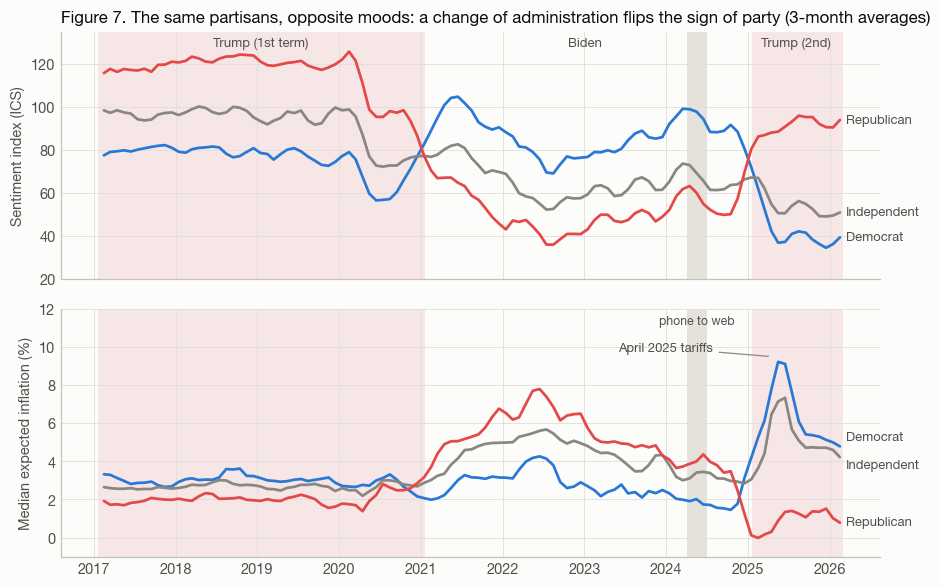

In [11]:
d7 = df[(df.YYYYMM >= 201702) & (df.WT > 0)].copy()
d7['party'] = d7.POLAFF.map({1: 'Republican', 2: 'Democrat', 3: 'Independent'})
d7['px'] = d7.PX1.where(d7.PX1.between(-95, 95))
ics_p = d7.dropna(subset=['party']).groupby(['YYYYMM', 'party']).apply(lambda g: np.average(g.ICS, weights=g.WT)).unstack()
px_p = d7.dropna(subset=['party', 'px']).groupby(['YYYYMM', 'party']).apply(lambda g: grouped_median(g.px, g.WT)).unstack()
fig, axs = plt.subplots(2, 1, figsize=(10, 6.2), sharex=True)
for ax, tab, yl in [(axs[0], ics_p, 'Sentiment index (ICS)'), (axs[1], px_p, 'Median expected inflation (%)')]:
    for a, b in [('2017-01-20', '2021-01-20'), ('2025-01-20', '2026-03-01')]: ax.axvspan(T(a), T(b), color='#f6e7e6', lw=0, zorder=0)
    ax.axvspan(T('2024-04-01'), T('2024-07-01'), color='#e4e2db', lw=0, zorder=0)
    sm = tab.rolling(3, min_periods=1).mean(); x = ym_to_date(sm.index.values)
    for p in ['Democrat', 'Independent', 'Republican']: ax.plot(x, sm[p], color=PARTY[p], lw=1.8)
    ax.set_ylabel(yl)
ends = ics_p.rolling(3, min_periods=1).mean().iloc[-1]
for p in PARTY: axs[0].text(x.iloc[-1] + pd.Timedelta(days=25), ends[p], p, va='center', fontsize=8.5, color=INK2)
ends = px_p.rolling(3, min_periods=1).mean().iloc[-1]
for p, dy in [('Democrat', 0.45), ('Independent', -0.45), ('Republican', 0)]:
    axs[1].text(x.iloc[-1] + pd.Timedelta(days=25), ends[p] + dy, p, va='center', fontsize=8.5, color=INK2)
for lab, dte in [('Trump (1st term)', '2019-01-15'), ('Biden', '2023-01-01'), ('Trump (2nd)', '2025-08-01')]:
    axs[0].text(T(dte), 128, lab, ha='center', fontsize=8.5, color=INK2)
axs[0].set_ylim(20, 135); axs[1].set_ylim(-1, 12)
axs[1].text(T('2024-05-15'), 11.2, 'phone to web', ha='center', fontsize=8, color=INK2)
axs[1].annotate('April 2025 tariffs', xy=(T('2025-04-15'), 9.5), xytext=(T('2023-06-01'), 9.8), fontsize=8.5, color=INK2,
                arrowprops=dict(arrowstyle='-', color=MUTED, lw=0.8))
axs[0].set_title('Figure 7. The same partisans, opposite moods: a change of administration flips the sign of party (3-month averages)')
fig.subplots_adjust(right=0.87, hspace=0.12); plt.show()

Each change in the White House reverses the partisan gap. Under the first Trump administration Republicans were about 40 index points more optimistic than Democrats; under Biden the order reversed; after the November 2024 election it reversed again, within weeks. The inflation panel shows the same pattern with an additional shock: after the April 2025 tariff announcements, Democrats' median expected inflation passed 9% while Republicans' stayed near 1%.

The table below quantifies this for the 2017–2024 telephone months, when party was asked every month. It adds party identification to the within-month model, first as a fixed effect and then interacted with which party held the presidency.

In [12]:
dp = df[(df.YYYYMM.between(201702, 202403))].copy()
dp['party'] = dp.POLAFF.map({1: 'R', 2: 'D', 3: 'I'}); dp['regime'] = np.where(dp.YYYYMM < 202102, 'R', 'D')
out = []
for q in SCORED:
    d = dp.dropna(subset=['y_' + q, 'party'] + DEMO).copy(); y = d['y_' + q]; tot = y.var()
    yc = y - d.groupby('YYYYMM')['y_' + q].transform('mean')
    def r2(X):
        Xc = demean_by_month(d, X); b, *_ = np.linalg.lstsq(Xc.values, yc.values, rcond=None)
        return 1 - (yc.values - Xc.values @ b).var() / yc.var()
    Xd = pd.get_dummies(d[DEMO].astype(int).astype(str), drop_first=True).astype(float)
    a = r2(Xd); b = r2(pd.concat([Xd, pd.get_dummies(d.party, drop_first=True).astype(float)], axis=1))
    c = r2(pd.concat([Xd, pd.get_dummies(d.party + '_' + d.regime, drop_first=True).astype(float)], axis=1))
    w = yc.var() / tot
    out.append(dict(question=SCORED[q][0], month=1 - w, party=(b - a) * w, party_x_presidency=(c - b) * w))
print((pd.DataFrame(out).set_index('question').sort_values('party_x_presidency', ascending=False) * 100).round(1).to_string())

                                              month  party  party_x_presidency
question                                                                      
Government economic policy                      4.1    0.3                22.0
Business conditions a year from now             4.5    0.2                11.3
Business conditions, next 12 months             9.7    0.4                11.1
Business conditions, next 5 years               2.7    0.7                 9.7
Unemployment next year (less = favourable)      4.9    0.5                 8.6
Business conditions vs a year ago              17.1    0.1                 8.2
Personal finances a year from now               3.4    0.1                 4.2
Personal finances vs a year ago                 6.2    0.1                 3.6
Expected inflation, next 12 months (%)          7.9    0.6                 3.2
Real income next 1–2 years                      2.0    0.1                 2.1
Interest rates next year (down = favourable)   15.1 

Party on its own explains almost nothing (under 1% of the variance of any question), because Republicans and Democrats swap places when power changes hands. Party *interacted with the presidency* explains 22% of the variance of the government-policy question and about 11% for the business-conditions questions, more than the month itself. A predictor that conditions on a fixed persona, including party, cannot capture this unless it also knows the political state. This is the clearest evidence in the file that the answers of interest are state-dependent in the strong sense: the state changes the mapping from person to answer, not only the average answer.

## 1.7 What to remember about the data

* One row is one interview in one survey month; `(YYYYMM, ID)` is the key, and about 36% of rows link to the same person's interview six months earlier.
* A stable core of about two dozen questions has been asked monthly since 1978; party identification only since February 2017.
* Values follow a 1 / 3 / 5 direction code with 8 / 9 (or 98 / 99, 998 / 999) for "don't know" and "not ascertained"; blanks mean "not asked".
* Use `WT` for anything population-level; with it, the file reproduces the official indexes.
* The 2024 move to the web changed answer distributions sharply for some questions (above all the middle option of `BUS12` and `BUS5`); only April–June 2024 identify the mode effect.
* For most questions the economic state explains more of an individual's answer than demographics do, and partisanship matters only through its interaction with who governs.
* The respondent-level archive ends in February 2026, although later months have been fielded and published as aggregates.

# Part 2. Proposal for a one-day MVP

> **Status: tentative.** This part proposes a design to be discussed and pre-registered before any LLM is run. Numbers from the dry run in Section 2.8 come from the non-LLM side only and are there to show that the cut works and to set the bar the twins have to clear.

## 2.1 The question

Can LLM-based digital twins predict survey answers that depend on the economic state better than supervised models do, and does any advantage grow as the state becomes more novel relative to what the supervised models were trained on? The proposed mechanism is that an LLM's general knowledge of how people react to events can stand in for training data from a regime that has not been observed.

Three kinds of change between training and test data need to be kept apart, because they favour different methods.

* **Covariate shift**: the measured state moves outside the training range (inflation at 9% when training saw 0% to 3%).
* **Concept shift**: the mapping from person and state to answer changes. It can have a *precedent* in the training data (the partisan flip of November 2024 repeats that of 2020–21) or *none* (the 2025 tariff shock, which arrived through announcements and news while realised inflation was still about 2.5%).
* **Measurement shift**: the instrument changes (the 2024 web transition). This hurts every method and is a nuisance, not novelty.

Two neighbouring literatures frame the contribution. Simulation work with individual twins compares twin configurations with one another on mostly trait-like outcomes; the one study that adds supervised baselines finds twins roughly equivalent to a gradient-boosted model trained on about 200 people (Peng et al., 2025). Work that simulates economic expectations with LLMs reports distributional fit, usually without supervised baselines and often with retrieval or anchoring on recent data; the closest is a 2025 simulation of the Michigan survey (Lin, Sun and Yan), and a Bank of England study uses GPT-3.5's September 2021 cutoff as a natural experiment around the 2022 inflation surge (Anesti, Hill and Joseph). Independent tests are sobering: Pew (2026) finds synthetic respondents stuck at pre-cutoff opinion levels while measured opinion moved. No published study compares individual-level twins with supervised models on this survey, or varies regime novelty deliberately.

## 2.2 Is it doable?

Yes, with a clearly stated scope. The binding constraint is the overlap between three things: months whose microdata exist, months after a model's knowledge cutoff, and months that contain a change of regime.

**Models.** A twin is only evaluated on months after its training cutoff, so cutoffs determine the evaluation window. The table lists the candidates that matter for this survey. The decisive fact in October 2026 is access rather than cutoffs: hosted access to early-cutoff models is being withdrawn, so open weights that can be self-hosted are the only durable option.

| Model | Stated cutoff | Open weights | Token log-probabilities | Role and caveats |
|---|---|---|---|---|
| Llama 3.1 8B and 70B Instruct | Dec 2023 | Yes | Yes (top 20 hosted; any number self-hosted) | **Primary twins.** Released July 2024; independent tests suggest knowledge thins out after early 2023. |
| Llama 3.3 70B Instruct | Dec 2023 | Yes | Yes | Stronger, but post-trained up to its December 2024 release; sensitivity check only. |
| gpt-4o (2024-08-06) | Oct 2023 | No | Yes (top 20) | Optional stronger check on a subsample. API shuts down 14 January 2027, so any run must be done and archived before then. |
| OLMo 2 13B / 32B | Dec 2023 | Yes, with open training data | Yes (self-hosted) | Weaker, but the training corpus can be searched for leaked survey results. |
| Gemma 3 27B, Llama 4, Phi-4, gpt-oss | Jun–Aug 2024 | Yes | Yes (self-hosted) | Clean only from about September 2024; useful for the 2025 shock. |
| Claude Haiku / Sonnet / Opus 4.5 | Training data to mid-2025 | No | No | Clean only from late 2025, and only with sampled answers (no log-probabilities). |
| gpt-3.5-turbo-0125 | Sep 2021 | No | Yes | The only strong instruction model clean for the 2021–22 inflation surge; the API shuts down 23 October 2026. |
| PIT-4B, ChronoGPT | Monthly or yearly vintages | Yes | Yes | Chronologically consistent by construction but at most about 4B parameters; usable as fine-tuned predictors, not zero-shot personas. |

**Data in the clean window.** For a December 2023 cutoff the clean window is January 2024 to February 2026: 26 months and 26,603 interviews, of which 23,440 were on the web and 8,253 are linked re-interviews. It contains two regime changes (the November 2024 election and the 2025 tariff shock) and the mode change. Figure 8 puts these pieces on one timeline, together with the proposed cut.

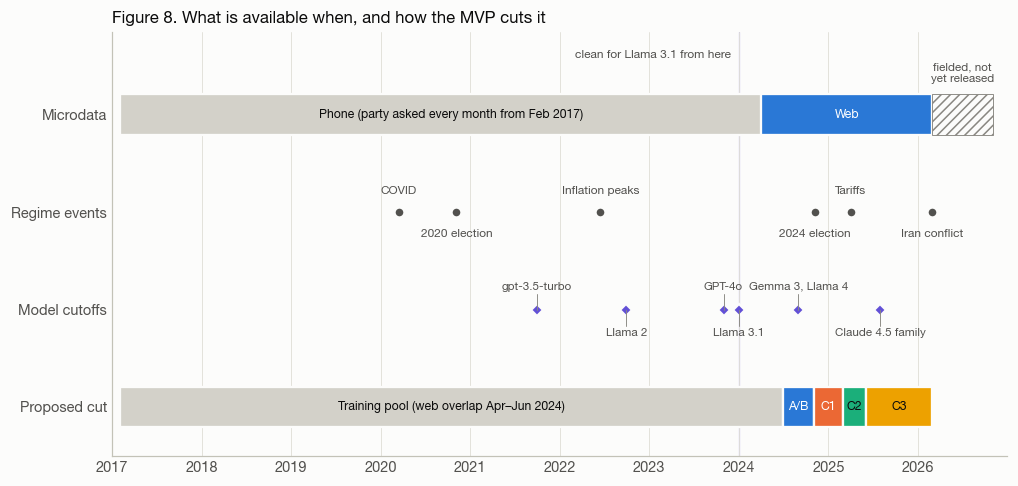

In [13]:
fig, ax = plt.subplots(figsize=(10.5, 5.0))
lanes = {'Microdata': 4, 'Regime events': 3, 'Model cutoffs': 2, 'Proposed cut': 1}
def lane_bar(lane, a, b, color, label=None, hatch=None, txt=INK):
    ax.barh(lanes[lane], (T(b) - T(a)).days, left=T(a), height=0.42, color=color, hatch=hatch,
            edgecolor=MUTED if hatch else SURFACE, linewidth=0.6 if hatch else 1.5)
    if label: ax.text(T(a) + (T(b) - T(a)) / 2, lanes[lane], label, ha='center', va='center', fontsize=8, color=txt)
lane_bar('Microdata', '2017-02-01', '2024-07-01', NEUTRAL, 'Phone (party asked every month from Feb 2017)')
lane_bar('Microdata', '2024-04-01', '2026-03-01', BLUE, 'Web', txt='white')
lane_bar('Microdata', '2026-03-01', '2026-11-01', SURFACE, hatch='////')
ax.text(T('2026-07-01'), 4.32, 'fielded, not\nyet released', ha='center', va='bottom', fontsize=7.6, color=INK2)
lane_bar('Proposed cut', '2017-02-01', '2024-07-01', NEUTRAL, 'Training pool (web overlap Apr–Jun 2024)')
lane_bar('Proposed cut', '2024-07-01', '2024-11-01', BLUE, 'A/B', txt='white')
lane_bar('Proposed cut', '2024-11-01', '2025-03-01', ORANGE, 'C1', txt='white')
lane_bar('Proposed cut', '2025-03-01', '2025-06-01', AQUA, 'C2')
lane_bar('Proposed cut', '2025-06-01', '2026-03-01', YELLOW, 'C3')
for dte, lab, up in [('2020-03-15', 'COVID', 1), ('2020-11-05', '2020 election', -1), ('2022-06-15', 'Inflation peaks', 1),
                     ('2024-11-05', '2024 election', -1), ('2025-04-02', 'Tariffs', 1), ('2026-02-28', 'Iran conflict', -1)]:
    ax.plot([T(dte)], [3], 'o', ms=7, color=INK2, mec=SURFACE, mew=2)
    ax.text(T(dte), 3 + 0.17 * up, lab, ha='center', va='bottom' if up > 0 else 'top', fontsize=7.8, color=INK2)
for dte, lab, lvl in [('2021-09-30', 'gpt-3.5-turbo', 0.3), ('2022-09-30', 'Llama 2', -0.3), ('2023-10-31', 'GPT-4o', 0.3),
                      ('2023-12-31', 'Llama 3.1', -0.3), ('2024-08-31', 'Gemma 3, Llama 4', 0.3), ('2025-07-31', 'Claude 4.5 family', -0.3)]:
    ax.plot([T(dte)], [2], 'D', ms=6, color=VIOLET, mec=SURFACE, mew=1.5)
    ax.plot([T(dte), T(dte)], [2, 2 + lvl * 0.55], color=MUTED, lw=0.6)
    ax.text(T(dte), 2 + lvl * 0.62, lab, ha='center', va='bottom' if lvl > 0 else 'top', fontsize=7.6, color=INK2)
ax.axvline(T('2023-12-31'), color=VIOLET, lw=0.8, alpha=0.45, zorder=0)
ax.text(T('2023-12-01'), 4.62, 'clean for Llama 3.1 from here', fontsize=7.8, color=INK2, va='center', ha='right')
ax.set_yticks(list(lanes.values())); ax.set_yticklabels(list(lanes.keys())); ax.set_ylim(0.5, 4.85)
ax.set_xlim(T('2017-01-01'), T('2026-12-31')); ax.grid(axis='y', visible=False)
ax.set_title('Figure 8. What is available when, and how the MVP cuts it')
plt.show()

**Limitations that shape the design.**

1. *Few regimes.* The clean window has two regime changes. Individual-level samples are large, but any claim about "novelty" rests on a handful of episodes, so the MVP treats them as pre-registered case studies and adds a month-by-month novelty gradient rather than claiming a regression across regimes.
2. *The mode change sits inside the window.* All test months are therefore web months, and every model learns the mode effect only from April–June 2024.
3. *The best clean models are not frontier models.* Llama 3.1 70B is the strongest open model with a December 2023 cutoff. Frontier models enter cleanly only for later regimes (Section 2.10).
4. *The archive lags.* March 2026 onward has been fielded (and includes a third shock, the 2026 oil-price spike) but is not yet released.
5. *Hosted access is disappearing.* The MVP must be able to run on self-hosted open weights, and all raw model outputs should be archived.

## 2.3 MVP design at a glance

* **Targets.** Four questions: `BUS12` (national, state- and party-dependent), `PX1` (year-ahead inflation in five bins), `PEXP` (own finances, the least state-dependent contrast case) and `GOVT` (the most partisan).
* **Families.** Zero-shot twins (Llama 3.1 8B and 70B Instruct) and supervised models (multinomial logit and gradient boosting), with persistence and climatology as reference forecasts.
* **Matched information ladder.** Both families see the same four information sets: profile only; profile plus macro state; profile plus news; profile plus both. A panel add-on gives re-interviewed respondents' answers from six months earlier to both families.
* **Tiers of out-of-sample-ness.** *A*, in-time (random respondents within the test months); *B*, out-of-time in the same regime (July–October 2024); *C*, out-of-regime (November 2024 to February 2026), split into the election flip (C1), the tariff shock (C2) and the aftermath (C3).
* **Two protocols.** *Fixed origin*, where models are frozen before the test period, answers "how good is a model with no data from the new regime?". *Rolling origin*, where the supervised model is retrained every month and the twin is anchored to last month's answers, answers "does the twin add anything when last month's survey is available?".
* **Scoring.** Proper scores at the individual level (log loss, Brier) and total variation distance (TVD) between predicted and actual answer shares at the population and party level, always against the sampling floor and persistence.

## 2.4 Targets and data cut

The four targets are coded as follows; "don't know" and "not ascertained" are excluded from scoring (under 2% on the web).

| Target | Classes | Why it is included |
|---|---|---|
| `BUS12` | Good times (1, 2) / partly good, partly bad (3) / bad times (4, 5) | National outlook; month explains 11% and party × presidency another 11% |
| `PX1` | Down or no change (≤ 0) / up 1–2% / 3–4% / 5–9% / 10% or more | The headline expectation; moved most in the 2025 shock |
| `PEXP` | Better off / same / worse off | Personal and more trait-like; a twin advantage here would be surprising |
| `GOVT` | Good job / only fair / poor job | Pure concept shift: party × presidency explains 22% |

The respondent table is built below, together with the profile, the state features and the tier labels. State features are lagged to what was public when a survey month's interview window opened (monthly releases from the previous month, CPI from two months back); the October 2025 values that were never published are carried forward.

In [14]:
TARGETS = {'BUS12': ({1: 0, 2: 0, 3: 1, 4: 2, 5: 2}, ['Good times', 'Partly good, partly bad', 'Bad times']),
           'PEXP': ({1: 0, 3: 1, 5: 2}, ['Better off', 'About the same', 'Worse off']),
           'GOVT': ({1: 0, 3: 1, 5: 2}, ['Good job', 'Only fair', 'Poor job']),
           'PX1': (None, ['Down or no change', 'Up 1–2%', 'Up 3–4%', 'Up 5–9%', 'Up 10% or more'])}
d = df[df.YYYYMM >= 201702].copy()
for q, (mp, labs) in TARGETS.items():
    d['t_' + q] = (pd.cut(d.PX1.where(d.PX1.between(-95, 95)), [-100, 0, 2, 4, 9, 100], labels=False) if q == 'PX1' else d[q].map(mp))

# Respondent profile: the same information for both families
d['pid'] = np.select([(d.POLAFF == 1) & (d.POLREP == 1), d.POLAFF == 1, (d.POLAFF == 3) & (d.POLCRD == 1),
                      (d.POLAFF == 2) & (d.POLDEM == 1), d.POLAFF == 2, (d.POLAFF == 3) & (d.POLCRD == 5), d.POLAFF == 3],
                     ['Strong Republican', 'Republican', 'Independent, leans Republican', 'Strong Democrat', 'Democrat',
                      'Independent, leans Democrat', 'Independent'], 'Unknown')
d['side'] = np.select([d.pid.str.contains('Republican'), d.pid.str.contains('Democrat')], [1, -1], 0)
d['agebin'] = pd.cut(d.AGE, [0, 29, 39, 49, 59, 69, 120], labels=False).fillna(-1)
d['kids'] = d.NUMKID.clip(upper=2).fillna(-1); d['adults'] = d.NUMADT.where(d.NUMADT < 8).clip(upper=3).fillna(-1)
d['web'] = (d.METHOD == 2).astype(int)
PROFILE = ['agebin', 'SEX', 'EDUC', 'REGION', 'YTL5', 'MARRY', 'kids', 'adults', 'HOMEOWN', 'INVEST', 'pid']

# Economic state at the start of each interview window
cpi, core = read_fred('CPIAUCSL').interpolate(), read_fred('CPILFESL').interpolate()   # level gap only affects y/y
gas = read_fred('APU000074714'); monthly = lambda s: s.resample('MS').mean()
S = pd.DataFrame({'cpi_yoy': cpi.pct_change(12) * 100, 'core_yoy': core.pct_change(12) * 100,
                  'unrate': read_fred('UNRATE').ffill(), 'fedfunds': read_fred('FEDFUNDS'), 'gas': gas,
                  'gas_yoy': gas.pct_change(12) * 100, 'mort30': monthly(read_fred('MORTGAGE30US')),
                  'stocks_ret12': monthly(read_fred('NASDAQCOM')).pct_change(12) * 100,
                  'log_epu': np.log(read_fred('USEPUINDXM')), 'log_epu_trade': np.log(read_fred('EPUTRADE'))})
S['unrate_d12'] = S.unrate.diff(12)
S = S.shift(1); S[['cpi_yoy', 'core_yoy']] = S[['cpi_yoy', 'core_yoy']].shift(1)
S.index = S.index.year * 100 + S.index.month
MACRO = ['cpi_yoy', 'core_yoy', 'unrate', 'unrate_d12', 'gas', 'gas_yoy', 'mort30', 'fedfunds', 'stocks_ret12']
NEWS_IDX = ['log_epu', 'log_epu_trade']            # non-LLM, news-based indices (Baker, Bloom and Davis)
d = d.join(S[MACRO + NEWS_IDX], on='YYYYMM')

# Political control. The sitting president and the most recent election winner differ from November to January.
d['sitting_R'] = d.YYYYMM.map(lambda m: (201702 <= m <= 202101) or m >= 202502).astype(int)
d['winner_R'] = d.YYYYMM.map(lambda m: (201611 <= m <= 202010) or m >= 202411).astype(int)
d['copart_sitting'] = d.side * (2 * d.sitting_R - 1); d['copart_winner'] = d.side * (2 * d.winner_R - 1)
STATE = ['sitting_R', 'winner_R', 'copart_sitting', 'copart_winner']
RUNGS = {'R1 profile': PROFILE, 'R2 +macro': PROFILE + STATE + MACRO,
         'R3 +news': PROFILE + STATE + NEWS_IDX, 'R4 +both': PROFILE + STATE + MACRO + NEWS_IDX}

# Tiers
d['ab_test'] = d.YYYYMM.between(202407, 202410) & (np.random.default_rng(20261018).random(len(d)) < 0.30)
d['period'] = pd.cut(d.YYYYMM, [0, 202406, 202410, 202502, 202505, 209912],
                     labels=['Training pool', 'A/B', 'C1 election flip', 'C2 tariff shock', 'C3 aftermath']).astype(str)
d['linked'] = d.IDPREV.notna()
tab = d.groupby('period').agg(months=('YYYYMM', 'nunique'), interviews=('ID', 'size'), web=('web', 'sum'),
                              linked_reinterviews=('linked', 'sum'), first=('YYYYMM', 'min'), last=('YYYYMM', 'max'))
tab.loc['A/B test (30%)'] = [4, int(d.ab_test.sum()), int(d.ab_test.sum()), int((d.ab_test & d.linked).sum()), 202407, 202410]
print(tab.loc[['Training pool', 'A/B', 'A/B test (30%)', 'C1 election flip', 'C2 tariff shock', 'C3 aftermath']].to_string())

                  months  interviews    web  linked_reinterviews   first    last
period                                                                          
Training pool         89       55005   1395                22273  201702  202406
A/B                    4        3929   3929                   68  202407  202410
A/B test (30%)         4        1194   1194                   20  202407  202410
C1 election flip       4        3688   3688                 1136  202411  202502
C2 tariff shock        3        3767   3767                 1364  202503  202505
C3 aftermath           9       10661  10661                 4211  202506  202602


The cut works as follows.

* **Training pool** (February 2017 to June 2024; 55,005 interviews). Party is available every month, two administrations and one partisan flip are included, and the last three months contain both modes. Supervised models train here with a web indicator.
* **Tiers A and B** (July to October 2024: web, Biden administration, before the election). A fixed random 30% of these respondents (1,194) form the test set for both tiers. Almost none of them are linked re-interviews, because the web panel was only starting, so the panel add-on is evaluated in Tier C. In **Tier A** the supervised models also train on the other 70% of these months; in **Tier B** they stop at June 2024. The twins' predictions are identical in A and B, so the A-to-B comparison isolates how much the supervised models lose by not seeing the test months.
* **Tier C** (November 2024 to February 2026; 18,116 interviews, 6,711 with a linked earlier interview). Under the fixed-origin protocol, supervised models are trained through October 2024 and never updated. C1 (November 2024 to February 2025) is concept shift with a precedent; C2 (March to May 2025) is the tariff shock, without precedent; C3 (June 2025 to February 2026) is the period after it.

How novel are the test months? Figure 9 measures each month's state, as fed to the supervised models, against the training pool in standard deviations.

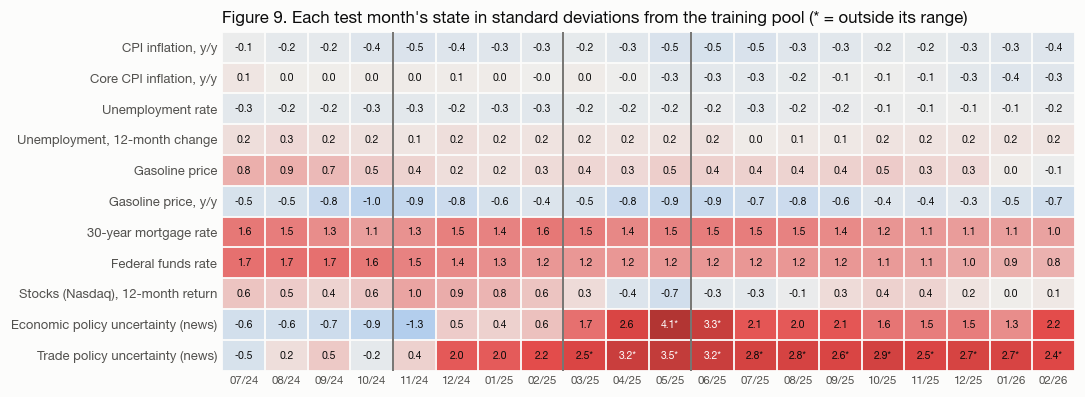

In [15]:
F = MACRO + NEWS_IDX
mm = d.groupby('YYYYMM')[F].first()
tr = mm.loc[201702:202410]; z = ((mm.loc[202407:202602] - tr.mean()) / tr.std()).T
outside = (mm.loc[202407:202602].gt(tr.max()) | mm.loc[202407:202602].lt(tr.min())).T
names = {'cpi_yoy': 'CPI inflation, y/y', 'core_yoy': 'Core CPI inflation, y/y', 'unrate': 'Unemployment rate',
         'unrate_d12': 'Unemployment, 12-month change', 'gas': 'Gasoline price', 'gas_yoy': 'Gasoline price, y/y',
         'mort30': '30-year mortgage rate', 'fedfunds': 'Federal funds rate', 'stocks_ret12': 'Stocks (Nasdaq), 12-month return',
         'log_epu': 'Economic policy uncertainty (news)', 'log_epu_trade': 'Trade policy uncertainty (news)'}
fig, ax = plt.subplots(figsize=(10, 4.0))
ax.imshow(z.values, cmap=DIV.reversed(), norm=TwoSlopeNorm(0, -4.5, 4.5), aspect='auto')
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        ax.text(j, i, f'{z.values[i, j]:.1f}' + ('*' if outside.values[i, j] else ''), ha='center', va='center', fontsize=6.8,
                color='white' if abs(z.values[i, j]) > 3 else INK)
ax.set_yticks(range(len(F))); ax.set_yticklabels([names[f] for f in F], fontsize=8.5)
ax.set_xticks(range(z.shape[1])); ax.set_xticklabels([f'{c % 100:02d}/{str(c // 100)[2:]}' for c in z.columns], fontsize=7.5, rotation=0)
for s in ax.spines.values(): s.set_visible(False)
ax.grid(False)
for x0 in np.arange(-0.5, z.shape[1], 1): ax.axvline(x0, color=SURFACE, lw=1.2)
for y0 in np.arange(-0.5, len(F), 1): ax.axhline(y0, color=SURFACE, lw=1.2)
for x0 in [3.5, 7.5, 10.5]: ax.axvline(x0, color=INK2, lw=1.0)
ax.set_title('Figure 9. Each test month\'s state in standard deviations from the training pool (* = outside its range)')
plt.show()

The figure makes an important point about the 2025 shock. **The hard data available at interview time were not unusual.** Inflation, unemployment, rates and gasoline prices in 2025 all stayed within the range of 2017–2024, which included the COVID recession and the 2022 inflation peak. What left the training range were the two news-based uncertainty indices, the trade index by a wide margin. The shock arrived as announcements and news before it reached any statistic. That is precisely where a model that reads text and knows what tariffs do might add something that a model trained on numbers cannot, and it is why the news rung matters.

## 2.5 The information ladder

Every rung gives the two families the same information, in text for the twins and as features for the supervised models. Rung 1 contains no time information at all; rungs 2 to 4 share a block describing the interview window and political control.

| Rung | Twin prompt contains | Supervised features | Isolates |
|---|---|---|---|
| R1 profile | Age, sex, education, region, household income, marital status, household composition, home ownership, stock ownership, seven-point party identification, and that the survey is online | The same, one-hot encoded, plus the web indicator | What a persona alone predicts |
| R2 + macro | R1, the interview window, the sitting president and the most recent election winner, and the latest official figures (CPI and core CPI, unemployment and its 12-month change, gasoline price and its change, mortgage and federal funds rates, 12-month stock return) | R1 plus the same numbers and political-control indicators (party of the sitting president and of the election winner, each interacted with the respondent's side) | Response to the measured state |
| R3 + news | R1, the window and political control, and a news digest: at most eight dated, factual bullets on the economy and economic policy from the four weeks before and during the window | R1 plus political control and two news-based uncertainty indices (overall and trade) | Response to events not yet in the data |
| R4 + both | R2 and R3 together | R2 and R3 together | The full information set |
| + P panel add-on | For linked re-interviews: the respondent's own four answers six months earlier, with that month named | The four lagged answers as features | What the person's own history adds |

Any supervised model that uses LLM-generated features, for example an LLM's score of the news digest, is labelled a **hybrid** and kept outside this comparison; it is an expansion (Section 2.10).

The twin prompt is ordered so that everything shared within a month comes first (instructions, window, figures, news) and the person and the question come last. This lets an inference server cache the shared prefix, which cuts compute several-fold. The cell below renders the prompt for an invented respondent placed in the April 2025 window, with that window's actual figures; the microdata's terms of use do not allow redistributing real respondents' records. The news digest is a short hand-written illustration; the MVP's digests are produced by the audited procedure in Section 2.7.

In [16]:
EDUC_TXT = {1: 'finished 8th grade or less', 2: 'some high school, no diploma', 3: 'a high-school diploma',
            4: 'some college but no degree', 5: 'a college degree', 6: 'a graduate or professional degree'}
REGION_TXT = {1: 'the West', 2: 'the Midwest', 3: 'the Northeast', 4: 'the South'}
MARRY_TXT = {1: 'married or living with a partner', 3: 'divorced or separated', 4: 'widowed', 5: 'never married'}
QUINT_TXT = {1: 'bottom fifth', 2: 'second fifth', 3: 'middle fifth', 4: 'fourth fifth', 5: 'top fifth'}
PID_TXT = {'Strong Republican': 'a strong Republican', 'Republican': 'a Republican, but not a strong one',
           'Independent, leans Republican': 'an independent who leans Republican', 'Independent': 'an independent',
           'Independent, leans Democrat': 'an independent who leans Democratic', 'Democrat': 'a Democrat, but not a strong one',
           'Strong Democrat': 'a strong Democrat', 'Unknown': 'none of the above'}
QUESTIONS = {
 'BUS12': ('Now turning to business conditions in the country as a whole -- do you think that during the next 12 months '
           "we'll have good times financially or bad times financially?",
           ['1. Good times financially during the next 12 months', '3. Partly good and partly bad',
            '5. Bad times financially during the next 12 months'], 'Answer with the number of your choice only.'),
 'PX1': ('During the next 12 months, do you think that prices in general will go up, or go down, or stay where they are now? '
         'By about what percent do you expect prices to go up or down, on average, during the next 12 months?', [],
         'Answer with one whole number only: the percent change (negative if prices will go down, 0 if they will stay where they are now).'),
}
def fmt_window(ym):
    w = win.set_index('YYYYMM').loc[ym]
    return pd.Timestamp(w.interview_start).strftime('%-d %B %Y'), pd.Timestamp(w.interview_end).strftime('%-d %B %Y')

def state_block(r):
    a, b = fmt_window(r.YYYYMM)
    pres = 'Donald Trump (Republican)' if r.sitting_R else 'Joe Biden (Democrat)'
    lines = [f'You are answering this survey between {a} and {b}. The President is {pres}.']
    if r.winner_R != r.sitting_R:
        lines.append('Donald Trump (Republican) won the November 2024 presidential election and takes office on 20 January 2025.')
    return '\n'.join(lines)

def macro_block(r):
    return ('Latest official figures at the time:\n'
            f'- Consumer prices were {r.cpi_yoy:.1f}% higher than a year earlier ({r.core_yoy:.1f}% excluding food and energy).\n'
            f'- The unemployment rate was {r.unrate:.1f}% ({r.unrate_d12:+.1f} points from a year earlier).\n'
            f'- Regular gasoline averaged ${r.gas:.2f} a gallon, {abs(r.gas_yoy):.0f}% {"higher" if r.gas_yoy >= 0 else "lower"} than a year earlier.\n'
            f'- The 30-year mortgage rate was {r.mort30:.2f}% and the federal funds rate {r.fedfunds:.2f}%.\n'
            f'- The stock market (Nasdaq Composite) had {"risen" if r.stocks_ret12 >= 0 else "fallen"} {abs(r.stocks_ret12):.0f}% over the past 12 months.')

def profile_block(r):
    kids = 'no children' if r.NUMKID == 0 else f'{int(r.NUMKID)} child' + ('ren' if r.NUMKID > 1 else '') + ' under 18'
    inc = f'about ${round(r.INCOME, -3):,.0f}' if pd.notna(r.INCOME) else 'not reported'
    sexw = {1: 'man', 2: 'woman'}.get(r.SEX, 'person')
    return ('About you:\n'
            f'- You are a {int(r.AGE)}-year-old {sexw} living in {REGION_TXT[r.REGION]}, and you have {EDUC_TXT[r.EDUC]}.\n'
            f'- You are {MARRY_TXT[r.MARRY]}; your household has {int(r.NUMADT)} adult{"s" if r.NUMADT > 1 else ""} and {kids}.\n'
            f'- Household income last year was {inc} (the {QUINT_TXT.get(r.YTL5, "unknown")} of U.S. households).\n'
            f'- You {"own" if r.HOMEOWN == 1 else "rent"} your home, and your household '
            f'{"has" if r.INVEST == 1 else "does not have"} money invested in the stock market.\n'
            f'- In politics you consider yourself {PID_TXT[r.pid]}.')

SYSTEM = ('You are taking part in the University of Michigan Surveys of Consumers, a monthly online survey of U.S. adults. '
          'You will be told who you are. Answer each question as that person would.')

def render(r, q, rung, digest=None, prior=None):
    parts = []
    if rung != 'R1 profile': parts.append(state_block(r))
    if rung in ('R2 +macro', 'R4 +both'): parts.append(macro_block(r))
    if rung in ('R3 +news', 'R4 +both') and digest: parts.append('Economic news in the weeks before and during the survey:\n' + digest)
    parts.append(profile_block(r))
    if prior: parts.append(prior)
    text, opts, instr = QUESTIONS[q]
    parts.append('Question: ' + text + ('\n' + '\n'.join(opts) if opts else '') + '\n' + instr)
    return f'[SYSTEM]\n{SYSTEM}\n\n[USER]\n' + '\n\n'.join(parts)

DIGEST_APR_2025 = '\n'.join([   # illustrative only
 '- 19 Mar: The Federal Reserve kept its policy rate at 4.25-4.50%.',
 '- 26 Mar: The President announced a 25% tariff on imported cars and light trucks, effective in early April.',
 '- 2 Apr: The President announced a tariff of at least 10% on imports from nearly all countries, with higher rates for dozens of trading partners.',
 '- 3-4 Apr: Stock prices fell sharply; the S&P 500 lost about 10% in two trading days. China announced retaliatory tariffs.',
 '- 4 Apr: The March jobs report showed 228,000 jobs added; the unemployment rate was 4.2%.',
 '- 9 Apr: The higher country-specific tariffs were paused for 90 days, the 10% tariff stayed, and tariffs on Chinese goods were raised further.'])

# An invented respondent, placed in the April 2025 window with that window's actual figures.
window_state = d[d.YYYYMM == 202504][['YYYYMM', 'sitting_R', 'winner_R'] + MACRO].iloc[0]
ex = pd.concat([window_state, pd.Series(dict(AGE=58, SEX=2, REGION=2, EDUC=4, MARRY=1, NUMADT=2, NUMKID=1, INCOME=85000,
                                             YTL5=3, HOMEOWN=1, INVEST=1, pid='Independent, leans Democrat'))])
print(render(ex, 'BUS12', 'R4 +both', digest=DIGEST_APR_2025))

[SYSTEM]
You are taking part in the University of Michigan Surveys of Consumers, a monthly online survey of U.S. adults. You will be told who you are. Answer each question as that person would.

[USER]
You are answering this survey between 25 March 2025 and 21 April 2025. The President is Donald Trump (Republican).

Latest official figures at the time:
- Consumer prices were 2.8% higher than a year earlier (3.1% excluding food and energy).
- The unemployment rate was 4.2% (+0.3 points from a year earlier).
- Regular gasoline averaged $3.23 a gallon, 10% lower than a year earlier.
- The 30-year mortgage rate was 6.65% and the federal funds rate 4.33%.
- The stock market (Nasdaq Composite) had risen 10% over the past 12 months.

Economic news in the weeks before and during the survey:
- 19 Mar: The Federal Reserve kept its policy rate at 4.25-4.50%.
- 26 Mar: The President announced a 25% tariff on imported cars and light trucks, effective in early April.
- 2 Apr: The President announced

The same respondent at rung 1 sees only the "About you" block and the question. With the panel add-on, a re-interviewed respondent's prompt gains one more block, placed after the profile (the earlier answers here are invented too):

In [17]:
BUS12_TXT = {1: 'good times', 2: 'good times', 3: 'partly good and partly bad times', 4: 'bad times', 5: 'bad times'}
earlier = dict(month='October 2024', BUS12=3, PX1=3)   # invented, like the profile
prior = (f'Six months ago, in {earlier["month"]}, you took this survey. You said that the country would have '
         f'{BUS12_TXT[earlier["BUS12"]]} financially during the next 12 months, and that prices would change by '
         f'{earlier["PX1"]}% over the next 12 months.')
print(render(ex, 'PX1', 'R1 profile', prior=prior))

[SYSTEM]
You are taking part in the University of Michigan Surveys of Consumers, a monthly online survey of U.S. adults. You will be told who you are. Answer each question as that person would.

[USER]
About you:
- You are a 58-year-old woman living in the Midwest, and you have some college but no degree.
- You are married or living with a partner; your household has 2 adults and 1 child under 18.
- Household income last year was about $85,000 (the middle fifth of U.S. households).
- You own your home, and your household has money invested in the stock market.
- In politics you consider yourself an independent who leans Democratic.

Six months ago, in October 2024, you took this survey. You said that the country would have partly good and partly bad times financially during the next 12 months, and that prices would change by 3% over the next 12 months.

Question: During the next 12 months, do you think that prices in general will go up, or go down, or stay where they are now? By about 

## 2.6 Models, protocols and scoring

**Twins.** Llama 3.1 8B Instruct and Llama 3.1 70B Instruct, used zero-shot. The answer distribution is read from the next-token log-probabilities rather than sampled. For the three-option questions the options are the single tokens `1`, `3` and `5`, and their probabilities are renormalised. For `PX1` the Llama 3 tokenizer encodes every integer from 0 to 999 as one token, so the next-token distribution over integers (plus the `-` token, assigned to the "down" bin) gives a full distribution over the answer, which is then binned; the probability mass covered by the top 20 tokens is reported, and a binned multiple-choice prompt is the fallback. Options appear in the web questionnaire's order and wording.

**Two derived twin variants**, both cheap and both honest about using data:

* *Calibrated twin*: a per-question vector scaling (temperature plus one bias per class) fitted on twin outputs for web respondents who are in the corresponding supervised training data (April–June 2024 for tiers A and B; April–October 2024 excluding the test 30% for Tier C). It learns the twin's level biases and the mode effect without touching its response to the state.
* *Anchored twin* (rolling protocol only, population and party level): last month's observed answer shares plus the twin's predicted change, *p̂ₜ = pₜ₋₁ + (q̄ₜ − q̄ₜ₋₁)*, renormalised. It uses the LLM only for the change, where the literature finds direction and ranking more reliable than levels.

**Supervised models.** A multinomial logistic regression (L2 penalty) and histogram gradient boosting, trained with survey weights on each rung's features. The two fail differently outside the training range: the logit extrapolates linearly, gradient boosting flattens at the edge. Reporting both keeps either failure mode from flattering the twins.

**Reference forecasts.** *Climatology*, the answer shares of the most recent training months in web mode; *persistence*, last month's observed shares, which is what a practitioner would use by default and is hard to beat in calm months.

**Protocols.**

* *Fixed origin*: supervised models frozen at the tier's training cut, twins zero-shot. This is the "simulate a period with no data of its own" use case.
* *Rolling origin* (Tier C): each month *t*, supervised models are retrained on everything through *t − 1*; persistence and the anchored twin are computed for the same month. This is the "nowcast before fieldwork" use case.

**Scores.**

* *Individual level*: weighted log loss (primary; it is a proper score and rewards calibrated distributions), Brier score, and top-1 accuracy for comparison with the twin literature. Each is reported as skill relative to climatology, *1 − loss / loss(climatology)*.
* *Population level*: for each month and question, the TVD between the weighted mean predicted distribution and the weighted observed shares; for `PX1` also the error in the median. A sampling floor (the expected TVD of a perfect predictor, estimated by split halves) is shown alongside.
* *Subgroup level*: the same TVD within Democrats, Republicans and independents, and the error in the Democrat–Republican gap in net balance. This is where concept shift shows up.
* *Uncertainty*: respondent bootstrap within months for individual scores; months as the unit for anything about regimes. With three months in C2, regime contrasts are reported descriptively.

**Pre-registered hypotheses.**

* *H1, novelty gradient.* The twin's advantage over the best supervised model (or its deficit) moves in the twin's favour from A to B to C, and from C1 (precedented) to C2 (unprecedented).
* *H2, mechanism.* Any twin advantage comes from rungs 2 to 4, not rung 1, and in C2 specifically from the news rung.
* *H3, anchoring.* The anchored twin beats persistence in break months (November 2024, February to April 2025) but not in calm months.
* *H4, people versus states.* The panel add-on helps both families by similar amounts; twins do not use a person's history better than a supervised model does.

## 2.7 Leakage and contamination controls

1. **Cutoff probe.** Before any run, each model is asked without context for the sentiment index and median expected inflation for every month from January 2022 to December 2025, ten times each. Errors are compared with a random walk; a model whose errors drop below the random walk after its stated cutoff is excluded. This takes a few hundred calls.
2. **News digests.** One digest per interview window (20 windows), written to a fixed template: only events dated within the four weeks before or during the window, one line each, factual, with a source URL; no polls, surveys, sentiment or expectations measures, and no knowledge of what came later. Each digest is drafted, checked by a second model against the rules and the window dates, and read by a person (about two hours in total). A term filter blocks "sentiment", "confidence", "expectations", "Michigan", "Conference Board" and "poll".
3. **Date-only check.** Rung 2 is also run with the figures removed (window and president only). For post-cutoff months this should not help; if it does, the model knows more about the date than it should.
4. **Archive everything.** All prompts, raw log-probabilities and model versions are stored, since several of the APIs involved shut down within months.

## 2.8 Dry run of the non-LLM side

The supervised half of the MVP is cheap, so it was run on the proposed cut to confirm that the design behaves sensibly and to see the bar the twins must clear. The cell below trains both supervised models on all four rungs for tiers A, B and C (fixed origin), plus gradient boosting with all features under the rolling protocol. It takes about four minutes.

In [18]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

def fit_predict(kind, feats, train, test, target):
    cat = [f for f in feats if f in PROFILE]; num = [f for f in feats if f not in PROFILE] + ['web']
    prep = ColumnTransformer([('c', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat), ('n', StandardScaler(), num)])
    est = (LogisticRegression(max_iter=400, C=0.5) if kind == 'GLM' else
           HistGradientBoostingClassifier(max_iter=150, learning_rate=0.08, max_leaf_nodes=31, random_state=0))
    model = make_pipeline(prep, est)
    X = lambda t: t[cat + num].astype({c: str for c in cat})
    model.fit(X(train), train[target].astype(int), **{model.steps[-1][0] + '__sample_weight': train.WT.values})
    P = np.zeros((len(test), len(TARGETS[target[2:]][1]))); P[:, model.classes_] = model.predict_proba(X(test))
    return P

t0 = time.time(); IND, DIST = [], []
for q in TARGETS:
    tq, K = 't_' + q, len(TARGETS[q][1])
    dq = d.dropna(subset=[tq]).copy(); dq[tq] = dq[tq].astype(int)
    pool = dq[(dq.YYYYMM <= 202406) & (dq.WT > 0)]
    ab = dq[dq.YYYYMM.between(202407, 202410)]; C = dq[dq.YYYYMM >= 202411]
    clim = wshare(pool[pool.web == 1][tq], pool[pool.web == 1].WT, range(K))
    tiers = {'A': (pd.concat([pool, ab[~ab.ab_test]]), ab[ab.ab_test]), 'B': (pool, ab[ab.ab_test]), 'C': (pd.concat([pool, ab]), C)}
    preds = {(t, k, r): fit_predict(k, f, *tiers[t], tq) for t in tiers for k in ['GLM', 'GBM'] for r, f in RUNGS.items()}
    roll = np.zeros((len(C), K))
    for m in sorted(C.YYYYMM.unique()):                     # rolling origin: retrain through t-1
        mask = (C.YYYYMM == m).values
        roll[mask] = fit_predict('GBM', RUNGS['R4 +both'], pd.concat([pool, ab, C[C.YYYYMM < m]]), C[mask], tq)
    preds[('C', 'GBM', 'R4 rolling')] = roll
    for (t, k, r), P in preds.items():
        test = tiers[t][1]
        for per, g in test.groupby('period'):
            i = test.index.get_indexer(g.index); y, w = g[tq].values, g.WT.values
            ll = -np.average(np.log(np.clip(P[i, y], 1e-6, 1)), weights=w)
            IND.append(dict(q=q, tier=t if t != 'C' else per, model=k, rung=r, logloss=ll,
                            skill=1 - ll / -np.average(np.log(clim[y]), weights=w),
                            accuracy=np.average(P[i].argmax(1) == y, weights=w), n=len(g)))
    for m in sorted(C.YYYYMM.unique()):
        g = C[C.YYYYMM == m]; i = C.index.get_indexer(g.index); w = g.WT.values
        act = wshare(g[tq], w, range(K)); prv = dq[dq.YYYYMM == prev_month(m)]
        row = dict(q=q, ym=m, persistence=0.5 * np.abs(wshare(prv[tq], prv.WT, range(K)) - act).sum())
        for (t, k, r), P in preds.items():
            if t == 'C': row[f'{k} {r}'] = 0.5 * np.abs(np.average(P[i], axis=0, weights=w) - act).sum()
        rs = np.random.default_rng(0); halves = []
        for _ in range(50):
            h = rs.random(len(g)) < 0.5
            halves.append(0.5 * np.abs(wshare(g[tq][h], w[h], range(K)) - wshare(g[tq][~h], w[~h], range(K))).sum())
        row['floor'] = np.mean(halves) / 2         # split-half TVD is about twice a full sample's error
        DIST.append(row)
IND, DIST = pd.DataFrame(IND), pd.DataFrame(DIST)
print(f'done in {time.time() - t0:.0f} s')

done in 242 s


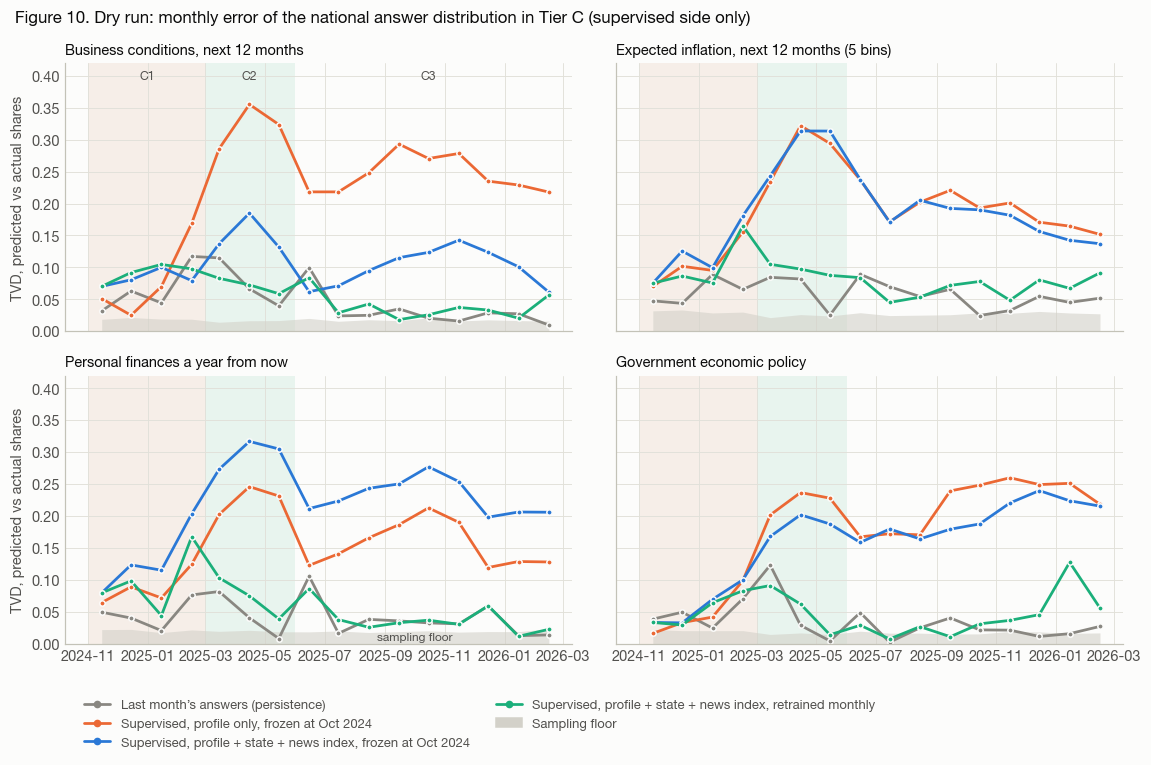

           persistence  GBM R1 profile  GBM R4 +both  GLM R4 +both  GBM R4 rolling  floor
q     sub                                                                                
BUS12 C1         0.064           0.079         0.083         0.118           0.091  0.019
      C2         0.074           0.322         0.151         0.288           0.071  0.016
      C3         0.032           0.245         0.099         0.260           0.039  0.017
GOVT  C1         0.046           0.047         0.059         0.128           0.052  0.021
      C2         0.052           0.222         0.186         0.218           0.056  0.015
      C3         0.024           0.220         0.196         0.211           0.041  0.017
PEXP  C1         0.047           0.087         0.130         0.132           0.097  0.021
      C2         0.043           0.227         0.298         0.280           0.072  0.020
      C3         0.038           0.155         0.230         0.212           0.038  0.019
PX1   C1  

In [19]:
QL = {'BUS12': 'Business conditions, next 12 months', 'PX1': 'Expected inflation, next 12 months (5 bins)',
      'PEXP': 'Personal finances a year from now', 'GOVT': 'Government economic policy'}
series = [('persistence', 'Last month’s answers (persistence)', MUTED),
          ('GBM R1 profile', 'Supervised, profile only, frozen at Oct 2024', ORANGE),
          ('GBM R4 +both', 'Supervised, profile + state + news index, frozen at Oct 2024', BLUE),
          ('GBM R4 rolling', 'Supervised, profile + state + news index, retrained monthly', AQUA)]
fig, axs = plt.subplots(2, 2, figsize=(10.5, 6.2), sharex=True, sharey=True)
for ax, q in zip(axs.flat, QL):
    g = DIST[DIST.q == q]; x = ym_to_date(g.ym.values)
    ax.axvspan(T('2024-11-01'), T('2025-03-01'), color='#f6eee8', lw=0, zorder=0)
    ax.axvspan(T('2025-03-01'), T('2025-06-01'), color='#e8f4ee', lw=0, zorder=0)
    ax.fill_between(x, 0, g.floor, color=NEUTRAL, alpha=0.6, lw=0)
    for k, lab, c in series: ax.plot(x, g[k], color=c, lw=1.8, marker='o', ms=3.5, mec=SURFACE, mew=1)
    ax.set_title(QL[q], fontsize=9.5); ax.set_ylim(0, 0.42)
for lab, dte in [('C1', '2025-01-01'), ('C2', '2025-04-15'), ('C3', '2025-10-15')]:
    axs[0, 0].text(T(dte), 0.395, lab, ha='center', fontsize=8, color=INK2)
axs[1, 0].text(T('2025-10-01'), 0.006, 'sampling floor', fontsize=7.8, color=INK2, ha='center')
for ax in axs[:, 0]: ax.set_ylabel('TVD, predicted vs actual shares')
fig.legend(handles=[Line2D([], [], color=c, lw=1.8, marker='o', ms=4, label=l) for _, l, c in series] + [Patch(color=NEUTRAL, label='Sampling floor')],
           loc='lower left', bbox_to_anchor=(0.06, -0.12), ncols=2, fontsize=8.5)
fig.suptitle('Figure 10. Dry run: monthly error of the national answer distribution in Tier C (supervised side only)',
             x=0.01, ha='left', fontsize=11, fontweight='semibold')
fig.tight_layout(); plt.show()

DIST['sub'] = pd.cut(DIST.ym, [0, 202502, 202505, 209912], labels=['C1', 'C2', 'C3'])
print(DIST.groupby(['q', 'sub'], observed=True)[['persistence', 'GBM R1 profile', 'GBM R4 +both', 'GLM R4 +both', 'GBM R4 rolling', 'floor']]
      .mean().round(3).to_string())

Figure 10 shows population-level error in Tier C. Frozen at October 2024, the supervised models with political-control features stay within one or two points of persistence on `BUS12` and `GOVT` through the election flip (C1), because the 2020–21 flip in the training pool shows them what a change of administration does; on `PX1` and `PEXP` they already drift in C1. All of them break down in the tariff shock. In C2 the best frozen configuration misses the national distribution by a TVD of 0.15 to 0.30, against a sampling floor of about 0.02, and it does not recover in C3. Persistence and the monthly-retrained model stay much closer to the floor, with their largest misses in the months the shock arrived (February to April 2025). The profile-only model is the worst predictor of `BUS12` and `GOVT` once power changes hands, which is the concept shift of Section 1.6 seen out of sample.

Figure 11 gives the individual-level picture: log-loss skill relative to the pre-test web answer shares, for every configuration and tier (blue is better than climatology, red is worse).

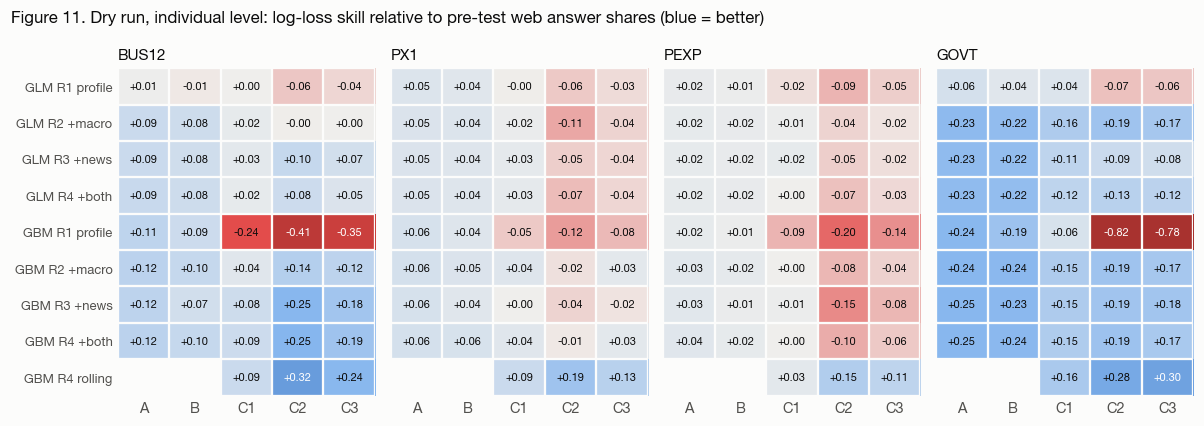

In [20]:
order = ['A', 'B', 'C1 election flip', 'C2 tariff shock', 'C3 aftermath']
rows = [(k, r) for k in ['GLM', 'GBM'] for r in RUNGS] + [('GBM', 'R4 rolling')]
fig, axs = plt.subplots(1, 4, figsize=(11, 3.9), sharey=True)
for ax, q in zip(axs, QL):
    P = IND[IND.q == q].pivot_table(index=['model', 'rung'], columns='tier', values='skill').reindex(rows)[order]
    ax.imshow(P.values, cmap=DIV, norm=TwoSlopeNorm(0, -0.5, 0.5), aspect='auto')
    for i in range(P.shape[0]):
        for j in range(P.shape[1]):
            v = P.values[i, j]
            if np.isfinite(v): ax.text(j, i, f'{v:+.2f}', ha='center', va='center', fontsize=7.2, color='white' if abs(v) > 0.3 else INK)
    ax.set_xticks(range(5)); ax.set_xticklabels(['A', 'B', 'C1', 'C2', 'C3']); ax.set_title(q, fontsize=10); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
    for y0 in np.arange(-0.5, len(rows), 1): ax.axhline(y0, color=SURFACE, lw=1.5)
    for x0 in np.arange(-0.5, 5, 1): ax.axvline(x0, color=SURFACE, lw=1.5)
axs[0].set_yticks(range(len(rows))); axs[0].set_yticklabels([f'{k} {r}' for k, r in rows], fontsize=8.5)
fig.suptitle('Figure 11. Dry run, individual level: log-loss skill relative to pre-test web answer shares (blue = better)',
             x=0.01, ha='left', fontsize=11, fontweight='semibold')
fig.tight_layout(); plt.show()

Four things follow for the twin side of the experiment.

1. **The supervised baselines are not straw men.** With political-control features they keep positive skill through the election flip, and with monthly retraining they recover from the tariff shock within a month or two. A twin has to beat these, not a demographics-only model.
2. **The room for twins is specific.** It is large under the fixed-origin protocol in C2 and C3, where frozen supervised models lose most of their skill or worse, and it is narrow under the rolling protocol, where only the break months leave a gap over persistence. The MVP should therefore expect, and report, different answers to the two practical questions.
3. **Individual-level skill is modest everywhere.** The best configurations reach a skill of 0.1 to 0.3, consistent with Section 1.6: most of an individual answer is transient. Population and subgroup scores are where differences between methods will be visible.
4. **On `PEXP` the frozen models fail in the wrong direction.** Adding state features makes them worse than the profile alone in C2 and C3, because the 2025 deterioration in people's personal outlook has no counterpart in how personal finances related to the measured economy in 2017–2024. This is where a twin that reads the news could add the most on a personal outcome, and also where a spurious win from a level bias is easiest, so calibrated and uncalibrated twins must both be reported.

## 2.9 Running it in a day

| Block | Hours | Work | Output |
|---|---|---|---|
| 1 | 0:00–1:00 | Freeze the respondent table, tiers and seeds from this notebook; write the pre-registration (targets, hypotheses, scores) | Frozen splits and a pre-registration note |
| 2 | 1:00–2:30 | Draft and audit the 20 news digests; run the cutoff probe on both models | Digests, leak-audit log, probe results |
| 3 | 2:30–3:30 | Twin harness: prompt renderer (Section 2.5), log-probability parser, caching and retries; 200-prompt smoke test checking option coverage | Working harness |
| 4 | 3:30–6:30 | Twin runs: 8B and 70B × four rungs × four questions on the A/B test set, 400 sampled respondents per Tier C month, and the calibration samples; panel add-on for linked re-interviews | About 410,000 scored prompts (calculator below) |
| 5 | 6:30–7:30 | Supervised runs (this notebook's code, all tiers, both protocols); calibrated and anchored twin variants | All predictions in one table |
| 6 | 7:30–9:30 | Scoring, bootstrap intervals, the headline figures (Figures 10 and 11 with the twins added, plus party-level panels), short write-up against H1–H4 | MVP results |

**Compute and cost.** The cell below counts the prompts the plan implies and prices them. The prices are indicative hosted rates seen in October 2026 for Llama 3.1 and 3.3 and must be checked on the day; availability is the bigger risk. The fallback is vLLM on one rented H100 (about $3 to $4 an hour), which also lifts the 20-alternative limit on log-probabilities; with the shared prefix cached, an estimated one hour for 8B and three to six hours for 70B in FP8. The optional gpt-4o check (100 respondents per Tier C month, rungs 1 and 4) adds about $20. The supervised models run on a laptop.

In [21]:
SAMPLE_PER_C_MONTH, RUNGS_N, QUESTIONS_N, TOKENS_PER_PROMPT = 400, 4, 4, 550
n_ab = int(d.ab_test.sum())
n_c = SAMPLE_PER_C_MONTH * d[d.YYYYMM >= 202411].YYYYMM.nunique()
n_cal = int(((d.web == 1) & (d.YYYYMM <= 202410) & ~d.ab_test).sum())          # web respondents in the training data
n_panel = int(n_c * d[d.YYYYMM >= 202411].linked.mean())
blocks = pd.DataFrame({'respondents': [n_ab, n_c, n_cal, n_panel],
                       'prompts per respondent': [RUNGS_N * QUESTIONS_N] * 3 + [2 * QUESTIONS_N]},
                      index=['A/B test set', 'Tier C sample', 'Calibration samples', 'Panel add-on (R1+P, R4+P)'])
blocks['prompts per model'] = blocks.respondents * blocks['prompts per respondent']
per_model = blocks['prompts per model'].sum(); mtok = per_model * TOKENS_PER_PROMPT / 1e6
print(blocks.to_string()); print(f'\nper model: {per_model:,} prompts, about {mtok:.0f}M input tokens; both models: {2 * per_model:,} prompts')
print(f'hosted cost per run: 8B about ${mtok * 0.02:,.0f} (at $0.02/M); 70B about ${mtok * 0.10:,.0f} to ${mtok * 0.25:,.0f} (at $0.10-0.25/M)')

                           respondents  prompts per respondent  prompts per model
A/B test set                      1194                      16              19104
Tier C sample                     6400                      16             102400
Calibration samples               4130                      16              66080
Panel add-on (R1+P, R4+P)         2370                       8              18960

per model: 206,544 prompts, about 114M input tokens; both models: 413,088 prompts
hosted cost per run: 8B about $2 (at $0.02/M); 70B about $11 to $28 (at $0.10-0.25/M)


## 2.10 After the MVP

Each extension below answers a question the MVP leaves open, in rough order of value per day of work.

1. **Human-equivalent sample size.** At each break month, retrain the supervised model with *k* respondents from that month added (*k* = 0, 25, 50, 100, 200, 400) and report the *k* at which it matches the twin. This turns "twins beat supervised" into "a twin is worth *k* interviews", the unit a survey buyer can act on.
2. **Fine-tuned twins.** LoRA fine-tuning of Llama 3.1 8B (and then 70B) on 2017–2024 respondents rendered with the rung-4 prompt, as in Kolluri et al. The question is whether fine-tuning keeps the model's prior about novel events or overwrites it with the training regime. Cost is about $5 to $45 per run.
3. **Hybrid models.** Let an LLM read the news digest and output a handful of numbers (for example, expected effects on prices and jobs), then feed these to the supervised models. This separates the LLM as a reader of news from the LLM as a simulator of people.
4. **Joint structure.** Score crosstabs and correlations between answers, and all 13 categorical questions, not only marginals. Simulators are known to compress variance and exaggerate inter-item correlations; this is where that would show.
5. **A third regime.** When the archive adds March 2026 onward, the Iran conflict and the oil-price spike provide a shock that is after the cutoff of every model listed above, including the Claude 4.5 family. Frontier models can then enter the comparison cleanly, using sampled answers instead of log-probabilities, and gas-price expectations (`GAS1`, `GAS5`) become a natural target.
6. **Prospective predictions.** Lodge twin predictions for survey months that have not yet been fielded (the November 2026 window opens on 20 October), published with a timestamp. Toplines arrive within weeks, microdata later. This is contamination-proof for any model.
7. **Earlier regimes, phone era.** The 2021–22 inflation surge and the 2021 partisan flip lie entirely in the phone era, so there is no mode change to handle. Clean twins for them are limited to gpt-3.5-turbo (until 23 October 2026), Llama 2 70B (clean from October 2022) and small chronologically consistent models used as fine-tuned predictors. With the right models, this doubles the number of regimes.
8. **Robustness.** Prompt framing (first person versus "predict this person"), reversed option order, persona format, and additional model families. Results in this literature move with configuration, so the configuration space should be reported, not searched.

## 2.11 Main risks

| Risk | Consequence | Response |
|---|---|---|
| Hosted endpoints for early-cutoff models disappear | Runs cannot be repeated | Self-host open weights; archive all outputs; run any closed-model check before its shutdown date |
| News digests leak hindsight | Twins look better than they are in C2 | Template, date checks, term filter, second-model audit, human read, and the date-only check |
| Llama 3.1 knows more about 2024 than its cutoff implies | Tier B and C1 contaminated | Cutoff probe; report results with and without models that fail it |
| Mode effect mis-estimated from three months | Level errors in all test months | Same bridge for both families; the calibrated-twin and climatology variants absorb levels; TVD on net balances as a robustness check |
| Few regimes | Hypotheses about novelty underpowered | Pre-register; report each episode; add regimes through extensions 5 to 7 |
| Partisan composition of the sample shifts | Population-level shifts partly compositional | Condition on party in all models; report party-level scores |

## References

* Park, J. S. et al. (2024, revised 2026). *LLM agents grounded in self-reports enable general-purpose simulation of individuals.* arXiv:2411.10109.
* Kolluri, A., Wu, S., Park, J. S., and Bernstein, M. S. (2025). *Finetuning LLMs for human behavior prediction in social science experiments.* EMNLP. arXiv:2509.05830.
* Peng, T., Gui, G., Toubia, O. et al. (2025). *Digital twins as funhouse mirrors.* arXiv:2509.19088.
* Lin, Sun and Yan (2025, revised 2026). *Simulating macroeconomic expectations using LLM agents.* arXiv:2505.17648.
* Anesti, Hill and Joseph (2025). *Inflation attitudes of large language models.* arXiv:2512.14306.
* Pew Research Center (2026). *Can AI stand in for human survey-takers? Not really.* 30 September 2026.
* Kim, J. and Lee, B. (2023, revised 2026). *AI-augmented surveys.* arXiv:2305.09620.
* Lopez-Lira, A., Tang, Y. and Zhu, M. (2025). *The memorization problem: can we trust LLMs' economic forecasts?* arXiv:2504.14765.
* Malmendier, U. and Nagel, S. (2016). Learning from inflation experiences. *Quarterly Journal of Economics* 131(1).
* Surveys of Consumers (2024). *Technical documentation for the 2024 methodological transition to web surveys*; *Comparisons of variables collected by phone and web* (see `data/README.md`).
* Data: Surveys of Consumers, Survey Research Center, University of Michigan; copyright © 1946–2026 The Regents of the University of Michigan. Macro series from FRED, Federal Reserve Bank of St. Louis (series listed in `data/external/fred/README.md`).